# ECE 3715 Mini-Project 3: Random Vectors and the Multivariate Gaussian

## Team Members
- Trevor Cheng: Steps 1–3, Bonus A, `sample_mean_cov` and `is_valid_covariance`
- Andrew Ore: Steps 4–6, Bonus B, `gaussian_pdf` and `whitening_matrix`
- George Li: Steps 7–8, `lmmse_weights`, final integration and clean-kernel testing

## Seed
SEED = 836285155 (drawn Nov 18, 2026)

## Runtime
The last cell prints the total runtime of this run. The README records it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate
from scipy.stats import multivariate_normal
import time

from mp3lib import (
    sample_mean_cov,
    is_valid_covariance,
    gaussian_pdf,
    whitening_matrix,
    lmmse_weights
)

SEED = 836285155  # drawn 2026-11-18, do not change
rng = np.random.default_rng(SEED)

rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]

rng_bonus_A = rng.spawn(1)[0]
rng_bonus_B = rng.spawn(1)[0]

runtime_start = time.perf_counter()

# Step 1: Two Variables at Once

We study the joint density

$$
f_{X,Y}(x,y)=x+y,\qquad 0\le x\le1,\;0\le y\le1.
$$

The goal is to verify its normalization, marginals, conditional density, moments, covariance, correlation, and Monte Carlo behavior.

## Analytical Results

Normalization:

$$
\int_0^1\int_0^1(x+y)\,dy\,dx=1,
$$

so \(f_{X,Y}\) is a valid density.

The marginals are

$$
f_X(x)=\int_0^1(x+y)\,dy=x+\frac12,
$$

$$
f_Y(y)=\int_0^1(x+y)\,dx=y+\frac12.
$$

The conditional density is

$$
f_{Y|X}(y|x)=\frac{x+y}{x+\frac12}.
$$

At \(x=0.3\),

$$
f_{Y|X}(y|0.3)=\frac{0.3+y}{0.8}.
$$

The analytical moments are

$$
E[X]=E[Y]=\frac{7}{12},
\qquad
E[XY]=\frac13,
$$

$$
\operatorname{Var}(X)=\operatorname{Var}(Y)=\frac{11}{144},
$$

$$
\operatorname{Cov}(X,Y)=-\frac1{144},
\qquad
\rho_{X,Y}=-\frac1{11}.
$$

In [2]:
def joint_xy(x, y):
    x = np.asarray(x)
    y = np.asarray(y)
    inside = (0 <= x) & (x <= 1) & (0 <= y) & (y <= 1)
    return np.where(inside, x + y, 0.0)


def quad2d(function):
    return integrate.dblquad(
        lambda y, x: function(x, y),
        0, 1,
        lambda x: 0,
        lambda x: 1,
        epsabs=1e-12,
        epsrel=1e-12
    )


quadrature_results = {
    "Normalization": quad2d(lambda x, y: joint_xy(x, y)),
    "E[X]": quad2d(lambda x, y: x * joint_xy(x, y)),
    "E[Y]": quad2d(lambda x, y: y * joint_xy(x, y)),
    "E[XY]": quad2d(lambda x, y: x * y * joint_xy(x, y)),
    "E[X^2]": quad2d(lambda x, y: x**2 * joint_xy(x, y)),
    "E[Y^2]": quad2d(lambda x, y: y**2 * joint_xy(x, y)),
}

for name, (value, error) in quadrature_results.items():
    print(f"{name}: {value:.12f}, quadrature error estimate: {error:.3e}")

ex_quad = quadrature_results["E[X]"][0]
ey_quad = quadrature_results["E[Y]"][0]
exy_quad = quadrature_results["E[XY]"][0]
ex2_quad = quadrature_results["E[X^2]"][0]
ey2_quad = quadrature_results["E[Y^2]"][0]

var_x_quad = ex2_quad - ex_quad**2
var_y_quad = ey2_quad - ey_quad**2
cov_xy_quad = exy_quad - ex_quad * ey_quad
rho_quad = cov_xy_quad / np.sqrt(var_x_quad * var_y_quad)

print(f"Var(X): {var_x_quad:.12f}")
print(f"Var(Y): {var_y_quad:.12f}")
print(f"Cov(X,Y): {cov_xy_quad:.12f}")
print(f"Correlation: {rho_quad:.12f}")

Normalization: 1.000000000000, quadrature error estimate: 1.663e-14
E[X]: 0.583333333333, quadrature error estimate: 1.659e-14
E[Y]: 0.583333333333, quadrature error estimate: 9.240e-15
E[XY]: 0.333333333333, quadrature error estimate: 9.220e-15
E[X^2]: 0.416666666667, quadrature error estimate: 1.656e-14
E[Y^2]: 0.416666666667, quadrature error estimate: 6.468e-15
Var(X): 0.076388888889
Var(Y): 0.076388888889
Cov(X,Y): -0.006944444444
Correlation: -0.090909090909


In [3]:
grid = np.linspace(0, 1, 501)
X_grid, Y_grid = np.meshgrid(grid, grid, indexing="ij")
joint_grid = joint_xy(X_grid, Y_grid)

fX_numeric = integrate.trapezoid(joint_grid, grid, axis=1)
fY_numeric = integrate.trapezoid(joint_grid, grid, axis=0)

fX_analytic = grid + 0.5
fY_analytic = grid + 0.5

x_condition = 0.3
conditional_grid = (x_condition + grid) / (x_condition + 0.5)

conditional_integral, conditional_error = integrate.quad(
    lambda y: (x_condition + y) / (x_condition + 0.5),
    0, 1
)

print(f"Conditional integral at x=0.3: {conditional_integral:.12f}")
print(f"Conditional quadrature error: {conditional_error:.3e}")
print(f"Maximum fX grid error: {np.max(np.abs(fX_numeric - fX_analytic)):.3e}")
print(f"Maximum fY grid error: {np.max(np.abs(fY_numeric - fY_analytic)):.3e}")

Conditional integral at x=0.3: 1.000000000000
Conditional quadrature error: 1.110e-14
Maximum fX grid error: 2.220e-16
Maximum fY grid error: 8.882e-16


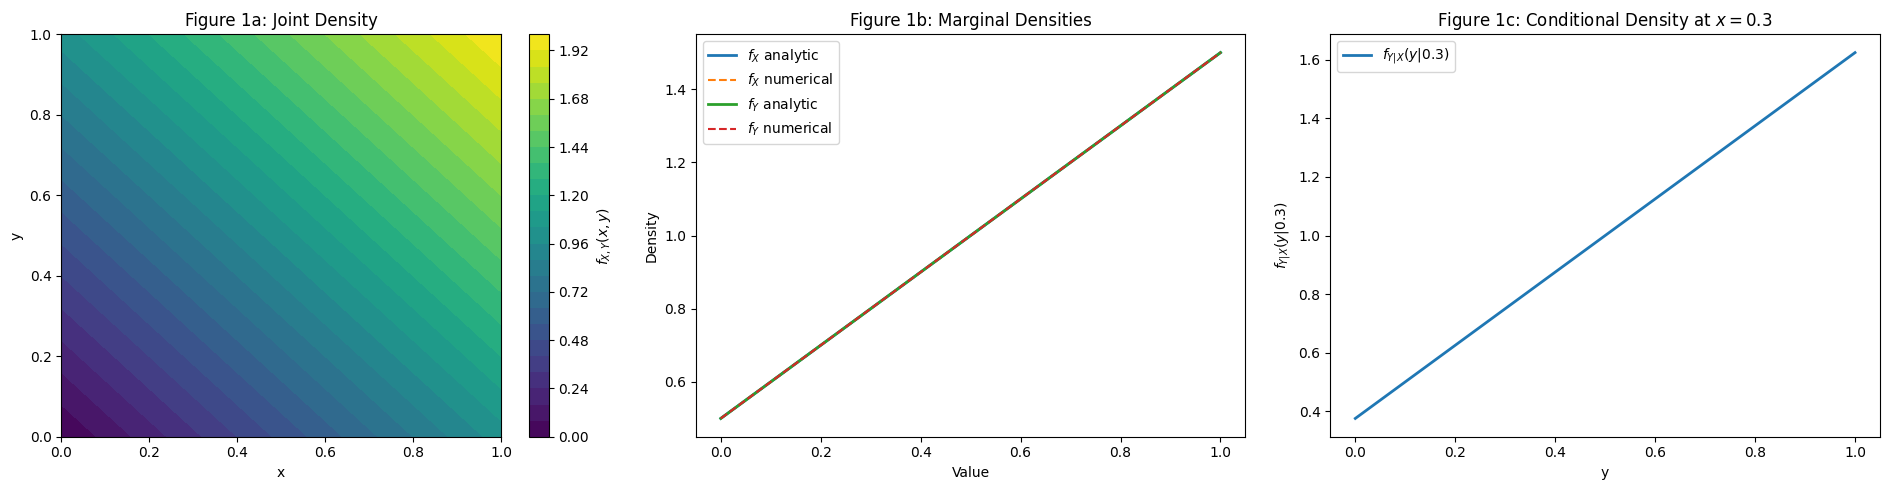

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Panel 1: joint density
contour = axes[0].contourf(
    X_grid,
    Y_grid,
    joint_grid,
    levels=30,
    cmap="viridis"
)

axes[0].set_title("Figure 1a: Joint Density")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
fig.colorbar(contour, ax=axes[0], label=r"$f_{X,Y}(x,y)$")

# Panel 2: marginals
axes[1].plot(
    grid,
    fX_analytic,
    label=r"$f_X$ analytic",
    linewidth=2
)

axes[1].plot(
    grid,
    fX_numeric,
    "--",
    label=r"$f_X$ numerical"
)

axes[1].plot(
    grid,
    fY_analytic,
    label=r"$f_Y$ analytic",
    linewidth=2
)

axes[1].plot(
    grid,
    fY_numeric,
    "--",
    label=r"$f_Y$ numerical"
)

axes[1].set_title("Figure 1b: Marginal Densities")
axes[1].set_xlabel("Value")
axes[1].set_ylabel("Density")
axes[1].legend()

# Panel 3: conditional density
axes[2].plot(
    grid,
    conditional_grid,
    label=r"$f_{Y|X}(y|0.3)$",
    linewidth=2
)

axes[2].set_title(r"Figure 1c: Conditional Density at $x=0.3$")
axes[2].set_xlabel("y")
axes[2].set_ylabel(r"$f_{Y|X}(y|0.3)$")
axes[2].legend()

fig.tight_layout()
plt.show()

## Figure 1 Interpretation

The heatmap shows that the density increases as either variable increases, but the normalized dependence produces a small negative correlation. The numerical marginal curves overlap the analytical curves, and the conditional density integrates to one as required.

In [5]:
N = 10**6
M = 2.0

accepted_chunks = []
accepted_total = 0
proposal_total = 0
batch_size = 2_000_000

while accepted_total < N:
    proposals = rng_step1.uniform(
        0,
        1,
        size=(batch_size, 2)
    )

    uniform_values = rng_step1.uniform(
        0,
        1,
        size=batch_size
    )

    acceptance_probability = (
        proposals[:, 0] + proposals[:, 1]
    ) / M

    accepted = uniform_values <= acceptance_probability

    accepted_chunks.append(proposals[accepted])
    accepted_total += np.count_nonzero(accepted)
    proposal_total += batch_size

samples_step1 = np.vstack(accepted_chunks)[:N]

x_samples = samples_step1[:, 0]
y_samples = samples_step1[:, 1]

acceptance_rate = accepted_total / proposal_total

print(f"Requested samples: {N:,}")
print(f"Total proposals: {proposal_total:,}")
print(f"Acceptance rate: {acceptance_rate:.6f}")
print("The bounding constant is M=2 because x+y <= 2 on the unit square.")

Requested samples: 1,000,000
Total proposals: 4,000,000
Acceptance rate: 0.499963
The bounding constant is M=2 because x+y <= 2 on the unit square.


In [6]:
analytic = {
    "E[X]": 7 / 12,
    "E[Y]": 7 / 12,
    "E[XY]": 1 / 3,
    "Var(X)": 11 / 144,
    "Var(Y)": 11 / 144,
    "Cov(X,Y)": -1 / 144,
    "Correlation": -1 / 11,
}

mean_x = np.mean(x_samples)
mean_y = np.mean(y_samples)
mean_xy = np.mean(x_samples * y_samples)

var_x = np.var(x_samples, ddof=1)
var_y = np.var(y_samples, ddof=1)

cov_xy = np.cov(
    x_samples,
    y_samples,
    ddof=1
)[0, 1]

correlation = cov_xy / np.sqrt(var_x * var_y)

se_mean_x = np.std(
    x_samples,
    ddof=1
) / np.sqrt(N)

se_mean_y = np.std(
    y_samples,
    ddof=1
) / np.sqrt(N)

se_mean_xy = np.std(
    x_samples * y_samples,
    ddof=1
) / np.sqrt(N)

se_var_x = np.std(
    (x_samples - analytic["E[X]"])**2,
    ddof=1
) / np.sqrt(N)

se_var_y = np.std(
    (y_samples - analytic["E[Y]"])**2,
    ddof=1
) / np.sqrt(N)

se_cov = np.std(
    (x_samples - analytic["E[X]"]) *
    (y_samples - analytic["E[Y]"]),
    ddof=1
) / np.sqrt(N)

rho = analytic["Correlation"]

gradient_cov = 1 / np.sqrt(
    analytic["Var(X)"] *
    analytic["Var(Y)"]
)

gradient_var_x = -rho / (
    2 * analytic["Var(X)"]
)

gradient_var_y = -rho / (
    2 * analytic["Var(Y)"]
)

influence_rho = (
    gradient_cov
    * (
        (x_samples - analytic["E[X]"]) *
        (y_samples - analytic["E[Y]"])
        - analytic["Cov(X,Y)"]
    )
    + gradient_var_x
    * (
        (x_samples - analytic["E[X]"])**2
        - analytic["Var(X)"]
    )
    + gradient_var_y
    * (
        (y_samples - analytic["E[Y]"])**2
        - analytic["Var(Y)"]
    )
)

se_correlation = np.std(
    influence_rho,
    ddof=1
) / np.sqrt(N)

sample_results = [
    ("E[X]", mean_x, se_mean_x),
    ("E[Y]", mean_y, se_mean_y),
    ("E[XY]", mean_xy, se_mean_xy),
    ("Var(X)", var_x, se_var_x),
    ("Var(Y)", var_y, se_var_y),
    ("Cov(X,Y)", cov_xy, se_cov),
    ("Correlation", correlation, se_correlation),
]

for name, estimate, standard_error in sample_results:
    difference = estimate - analytic[name]

    print(
        f"{name}: "
        f"estimate={estimate:.10f}, "
        f"analytic={analytic[name]:.10f}, "
        f"difference={difference:.3e}, "
        f"SE={standard_error:.3e}"
    )

E[X]: estimate=0.5831894622, analytic=0.5833333333, difference=-1.439e-04, SE=2.763e-04
E[Y]: estimate=0.5842683620, analytic=0.5833333333, difference=9.350e-04, SE=2.762e-04
E[XY]: estimate=0.3337833403, analytic=0.3333333333, difference=4.500e-04, SE=2.357e-04
Var(X): estimate=0.0763510136, analytic=0.0763888889, difference=-3.788e-05, SE=7.631e-05
Var(Y): estimate=0.0763119655, analytic=0.0763888889, difference=-7.692e-05, SE=7.620e-05
Cov(X,Y): estimate=-0.0069558185, analytic=-0.0069444444, difference=-1.137e-05, SE=7.480e-05
Correlation: estimate=-0.0911264642, analytic=-0.0909090909, difference=-2.174e-04, SE=9.708e-04


The density is slightly negatively correlated because, relative to the product of its marginals, it places more probability on cases where one variable is relatively high while the other is relatively low. The numerical statistics should agree with the analytical values within their reported standard errors.

# Step 2: Uncorrelated Does Not Mean Independent

Let

$$
X\sim \operatorname{Uniform}(-1,1),
\qquad
Y=X^2.
$$

Although \(X\) and \(Y\) are perfectly dependent, their covariance is zero.

## Analytical Results

Since \(X\) is uniform from \(-1\) to \(1\), its distribution is symmetric around zero. Therefore,

$$
E[X]=0
$$

and

$$
E[X^3]=0.
$$

Because \(Y=X^2\),

$$
E[Y]=E[X^2]=\frac13.
$$

Also,

$$
E[XY]=E[X^3]=0.
$$

Therefore,

$$
\operatorname{Cov}(X,Y)
=E[XY]-E[X]E[Y]
=0.
$$

The variances are

$$
\operatorname{Var}(X)=\frac13
$$

and

$$
\operatorname{Var}(Y)
=E[X^4]-E[X^2]^2
=\frac15-\frac19
=\frac4{45}.
$$

Even though the covariance is zero, \(Y=X^2\) is still completely determined by \(X\). Therefore, \(X\) and \(Y\) are dependent even though they are uncorrelated.

In [7]:
N_step2 = 10**7

X_step2 = rng_step2.uniform(
    -1,
    1,
    size=N_step2
)

Y_step2 = X_step2**2

mean_x_step2 = np.mean(X_step2)
mean_y_step2 = np.mean(Y_step2)

var_x_step2 = np.mean(
    (X_step2 - mean_x_step2)**2
)

var_y_step2 = np.mean(
    (Y_step2 - mean_y_step2)**2
)

cov_xy_step2 = np.mean(
    (X_step2 - mean_x_step2) *
    (Y_step2 - mean_y_step2)
)

correlation_step2 = cov_xy_step2 / np.sqrt(
    var_x_step2 * var_y_step2
)

# Delta-method standard error for the sample correlation
influence_correlation = (
    X_step2 * (Y_step2 - 1 / 3)
    / np.sqrt((1 / 3) * (4 / 45))
)

correlation_se_step2 = np.std(
    influence_correlation,
    ddof=1
) / np.sqrt(N_step2)

print(f"Number of samples: {N_step2:,}")
print(f"Sample E[X]: {mean_x_step2:.10f}")
print(f"Sample E[Y]: {mean_y_step2:.10f}")
print(f"Sample Var(X): {var_x_step2:.10f}")
print(f"Sample Var(Y): {var_y_step2:.10f}")
print(f"Sample Cov(X,Y): {cov_xy_step2:.10e}")
print(f"Sample correlation: {correlation_step2:.10e}")
print(f"Correlation standard error: {correlation_se_step2:.10e}")
print(
    f"Correlation divided by standard error: "
    f"{correlation_step2 / correlation_se_step2:.3f}"
)

Number of samples: 10,000,000
Sample E[X]: -0.0000500221
Sample E[Y]: 0.3332498035
Sample Var(X): 0.3332498010
Sample Var(Y): 0.0888573365
Sample Cov(X,Y): 6.3629927208e-06
Sample correlation: 3.6976843179e-05
Correlation standard error: 3.9628041975e-04
Correlation divided by standard error: 0.093


In [8]:
number_of_bins = 1000
bin_edges = np.linspace(-1, 1, number_of_bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

bin_indices = np.searchsorted(
    bin_edges,
    X_step2,
    side="right"
) - 1

bin_indices = np.clip(
    bin_indices,
    0,
    number_of_bins - 1
)

bin_counts = np.bincount(
    bin_indices,
    minlength=number_of_bins
)

bin_sums = np.bincount(
    bin_indices,
    weights=Y_step2,
    minlength=number_of_bins
)

bin_squared_sums = np.bincount(
    bin_indices,
    weights=Y_step2**2,
    minlength=number_of_bins
)

conditional_variance = np.full(
    number_of_bins,
    np.nan
)

valid_bins = bin_counts > 1

conditional_variance[valid_bins] = (
    bin_squared_sums[valid_bins]
    - bin_sums[valid_bins]**2 / bin_counts[valid_bins]
) / (bin_counts[valid_bins] - 1)

conditional_variance = np.maximum(
    conditional_variance,
    0
)

print(
    f"Maximum binned conditional variance: "
    f"{np.nanmax(conditional_variance):.10e}"
)

print(
    f"Median binned conditional variance: "
    f"{np.nanmedian(conditional_variance):.10e}"
)

Maximum binned conditional variance: 1.3447016989e-06
Median binned conditional variance: 3.3405608000e-07


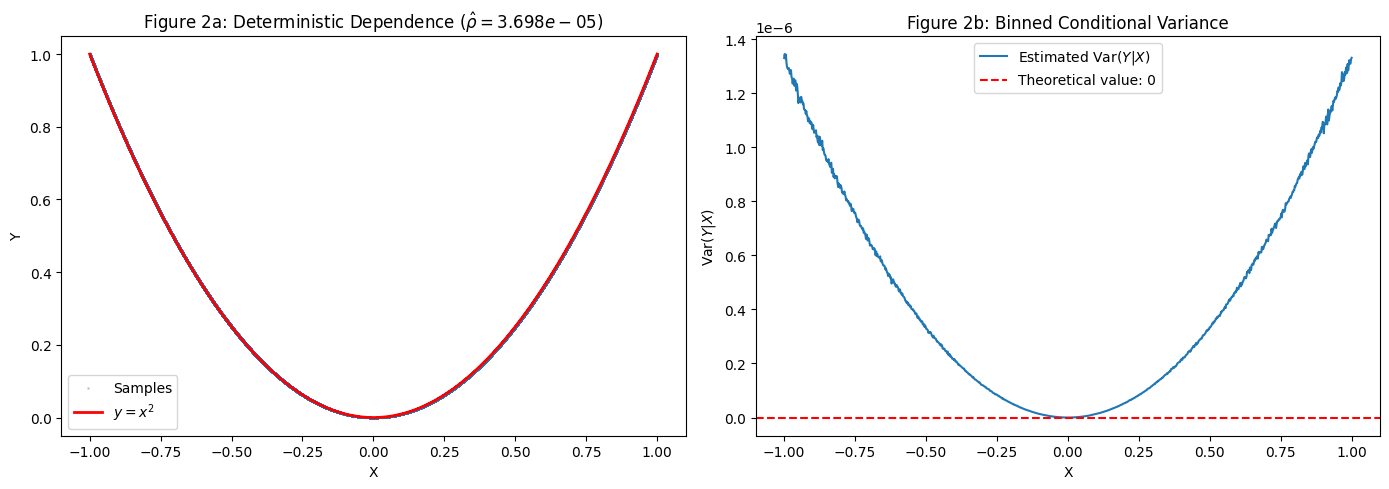

In [9]:
plot_count = 100_000

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Panel 1: scatter plot
axes[0].scatter(
    X_step2[:plot_count],
    Y_step2[:plot_count],
    s=1,
    alpha=0.25,
    label="Samples"
)

x_curve = np.linspace(-1, 1, 500)

axes[0].plot(
    x_curve,
    x_curve**2,
    color="red",
    linewidth=2,
    label=r"$y=x^2$"
)

axes[0].set_title(
    f"Figure 2a: Deterministic Dependence "
    f"($\\hat{{\\rho}}={correlation_step2:.3e}$)"
)

axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].legend()

# Panel 2: binned conditional variance
axes[1].plot(
    bin_centers,
    conditional_variance,
    label=r"Estimated $\operatorname{Var}(Y|X)$"
)

axes[1].axhline(
    0,
    color="red",
    linestyle="--",
    label="Theoretical value: 0"
)

axes[1].set_title(
    "Figure 2b: Binned Conditional Variance"
)

axes[1].set_xlabel("X")
axes[1].set_ylabel(r"$\operatorname{Var}(Y|X)$")
axes[1].ticklabel_format(
    axis="y",
    style="scientific",
    scilimits=(0, 0)
)
axes[1].legend()

fig.tight_layout()
plt.show()

## Figure 2 Interpretation

The points in the scatter plot fall exactly on the curve \(Y=X^2\). This shows that \(Y\) can be determined perfectly if \(X\) is known.

The estimated conditional variances are very close to zero. They are not exactly zero because each bin contains a small range of \(X\)-values instead of only one exact value. Using narrower bins makes the estimated variances even closer to zero.

The correlation is close to zero because the positive and negative values of \(X\) cancel each other when calculating covariance. This shows that correlation only measures linear relationships and can miss nonlinear relationships like \(Y=X^2\).

In [10]:
# Free memory from the first experiment before generating
# another 10^7-sample dataset.
del X_step2
del Y_step2
del bin_indices
del bin_counts
del bin_sums
del bin_squared_sums
del conditional_variance

gaussian_samples_step2 = rng_step2.multivariate_normal(
    mean=np.zeros(2),
    cov=np.eye(2),
    size=N_step2
)

GX_step2 = gaussian_samples_step2[:, 0]
GY_step2 = gaussian_samples_step2[:, 1]

del gaussian_samples_step2

histogram_edges = np.r_[
    -np.inf,
    np.linspace(-4, 4, 41),
    np.inf
]

joint_counts, _, _ = np.histogram2d(
    GX_step2,
    GY_step2,
    bins=(histogram_edges, histogram_edges)
)

x_counts, _ = np.histogram(
    GX_step2,
    bins=histogram_edges
)

y_counts, _ = np.histogram(
    GY_step2,
    bins=histogram_edges
)

empirical_joint_probability = joint_counts / N_step2

empirical_product_probability = (
    x_counts[:, None] * y_counts[None, :]
) / N_step2**2

absolute_difference = np.abs(
    empirical_joint_probability
    - empirical_product_probability
)

total_variation_distance = 0.5 * np.sum(
    absolute_difference
)

maximum_bin_difference = np.max(
    absolute_difference
)

print(
    f"Total variation distance between joint and product: "
    f"{total_variation_distance:.6e}"
)

print(
    f"Maximum binned probability difference: "
    f"{maximum_bin_difference:.6e}"
)

Total variation distance between joint and product: 2.927038e-03
Maximum binned probability difference: 5.533373e-05


## Gaussian Independence Check

The jointly Gaussian pair has zero correlation, so its two variables should be independent. To check this, the empirical joint probabilities were compared with the product of the empirical marginal probabilities.

The two distributions are very close. The small difference is caused by random sampling, so the results support the fact that zero correlation implies independence for jointly Gaussian variables.

For general random variables, being uncorrelated does not necessarily mean being independent. Covariance only measures whether two variables have a linear relationship, so it can miss nonlinear relationships.

For jointly Gaussian variables, the covariance matrix contains all of the dependence information. Therefore, if the correlation is zero, the variables are independent. This is useful in engineering because many estimation and modeling methods rely on the measurements being approximately Gaussian.

# Step 3: The Covariance Matrix and How Well You Can Estimate It

In this step, we use a four-dimensional covariance matrix to study how accurately covariance can be estimated from random samples. We will compare the estimation error for different sample sizes and check whether the error decreases at the expected rate.

## Covariance Matrix Setup

The covariance matrix used in this step is

$$
\Sigma=
\begin{bmatrix}
4 & 2 & 1 & 0\\
2 & 5 & 2 & 1\\
1 & 2 & 3 & 1\\
0 & 1 & 1 & 2
\end{bmatrix}.
$$

The matrix must be symmetric and positive semidefinite in order to be a valid covariance matrix.

In [11]:
Sigma_step3 = np.array([
    [4, 2, 1, 0],
    [2, 5, 2, 1],
    [1, 2, 3, 1],
    [0, 1, 1, 2]
], dtype=float)

mu_step3 = np.zeros(4)

eigenvalues_step3, eigenvectors_step3 = np.linalg.eigh(
    Sigma_step3
)

determinant_step3 = np.linalg.det(Sigma_step3)

print("Covariance matrix:")
print(Sigma_step3)

print("\nEigenvalues:")
for index, value in enumerate(eigenvalues_step3):
    print(f"lambda_{index + 1} = {value:.10f}")

print(f"\nDeterminant: {determinant_step3:.10f}")
print(
    f"Symmetric: "
    f"{np.allclose(Sigma_step3, Sigma_step3.T)}"
)
print(
    f"Valid covariance: "
    f"{is_valid_covariance(Sigma_step3)}"
)

Covariance matrix:
[[4. 2. 1. 0.]
 [2. 5. 2. 1.]
 [1. 2. 3. 1.]
 [0. 1. 1. 2.]]

Eigenvalues:
lambda_1 = 1.2648788942
lambda_2 = 1.7881953127
lambda_3 = 3.0980843219
lambda_4 = 7.8488414713

Determinant: 55.0000000000
Symmetric: True
Valid covariance: True


## Testing the Covariance Validation Function

The function should return `True` for the given covariance matrix. It should return `False` for a nonsymmetric matrix and for a symmetric matrix with a negative eigenvalue.

In [12]:
nonsymmetric_matrix = np.array([
    [1, 2],
    [0, 1]
], dtype=float)

negative_eigenvalue_matrix = np.array([
    [1, 0],
    [0, -0.5]
], dtype=float)

print(
    "Given matrix:",
    is_valid_covariance(Sigma_step3)
)

print(
    "Nonsymmetric matrix:",
    is_valid_covariance(nonsymmetric_matrix)
)

print(
    "Matrix with a negative eigenvalue:",
    is_valid_covariance(negative_eigenvalue_matrix)
)

print("\nEigenvalues of the negative-eigenvalue matrix:")
print(np.linalg.eigh(negative_eigenvalue_matrix)[0])

Given matrix: True
Nonsymmetric matrix: False
Matrix with a negative eigenvalue: False

Eigenvalues of the negative-eigenvalue matrix:
[-0.5  1. ]


## Covariance Estimates for Different Sample Sizes

Samples are generated from a four-dimensional Gaussian distribution with mean zero and covariance matrix \(\Sigma\). For each sample size, the Frobenius norm of the difference between the estimated covariance and the true covariance is calculated.

The Frobenius norm is

$$
\left\|\widehat{\Sigma}-\Sigma\right\|_F
=
\sqrt{
\sum_{i,j}
\left(
\widehat{\Sigma}_{ij}-\Sigma_{ij}
\right)^2
}.
$$

In [13]:
sample_sizes_step3 = np.array([
    10**2,
    10**3,
    10**4,
    10**5,
    10**6
])

single_draw_errors_step3 = []

for sample_size in sample_sizes_step3:
    samples = rng_step3.multivariate_normal(
        mean=mu_step3,
        cov=Sigma_step3,
        size=sample_size
    )

    _, estimated_covariance = sample_mean_cov(samples)

    error = np.linalg.norm(
        estimated_covariance - Sigma_step3,
        ord="fro"
    )

    single_draw_errors_step3.append(error)

    print(
        f"N = {sample_size:,}, "
        f"Frobenius error = {error:.10f}"
    )

single_draw_errors_step3 = np.array(
    single_draw_errors_step3
)

N = 100, Frobenius error = 1.1382809205
N = 1,000, Frobenius error = 0.4299013595
N = 10,000, Frobenius error = 0.1455729504
N = 100,000, Frobenius error = 0.0527204632
N = 1,000,000, Frobenius error = 0.0187766882


## Averaged Covariance Estimation Error

A single simulation at each sample size can be unusually high or low because of random variation. To see the general trend more clearly, the experiment is repeated many times and the errors are averaged.

The required numbers of repetitions are used for each sample size.

In [14]:
repetition_counts_step3 = {
    10**2: 200,
    10**3: 200,
    10**4: 100,
    10**5: 30,
    10**6: 10
}

average_errors_step3 = []
standard_deviations_step3 = []
standard_errors_step3 = []

for sample_size in sample_sizes_step3:
    errors_for_size = []

    for _ in range(repetition_counts_step3[sample_size]):
        samples = rng_step3.multivariate_normal(
            mean=mu_step3,
            cov=Sigma_step3,
            size=sample_size
        )

        _, estimated_covariance = sample_mean_cov(samples)

        error = np.linalg.norm(
            estimated_covariance - Sigma_step3,
            ord="fro"
        )

        errors_for_size.append(error)

    errors_for_size = np.array(errors_for_size)

    average_error = np.mean(errors_for_size)
    standard_deviation = np.std(
        errors_for_size,
        ddof=1
    )

    standard_error = (
        standard_deviation
        / np.sqrt(len(errors_for_size))
    )

    average_errors_step3.append(average_error)
    standard_deviations_step3.append(standard_deviation)
    standard_errors_step3.append(standard_error)

    print(
        f"N = {sample_size:,}, "
        f"repetitions = {len(errors_for_size)}, "
        f"average error = {average_error:.10f}, "
        f"standard deviation = {standard_deviation:.10f}, "
        f"standard error = {standard_error:.10f}, "
        f"sqrt(N)*error = "
        f"{np.sqrt(sample_size) * average_error:.10f}"
    )

average_errors_step3 = np.array(
    average_errors_step3
)

standard_deviations_step3 = np.array(
    standard_deviations_step3
)

standard_errors_step3 = np.array(
    standard_errors_step3
)

N = 100, repetitions = 200, average error = 1.5380964199, standard deviation = 0.4902543884, standard error = 0.0346662203, sqrt(N)*error = 15.3809641986
N = 1,000, repetitions = 200, average error = 0.4903160849, standard deviation = 0.1794388020, standard error = 0.0126882394, sqrt(N)*error = 15.5051560167


N = 10,000, repetitions = 100, average error = 0.1639154810, standard deviation = 0.0542429124, standard error = 0.0054242912, sqrt(N)*error = 16.3915480986


N = 100,000, repetitions = 30, average error = 0.0469080011, standard deviation = 0.0224506781, standard error = 0.0040989143, sqrt(N)*error = 14.8336123923


N = 1,000,000, repetitions = 10, average error = 0.0146042161, standard deviation = 0.0038476632, standard error = 0.0012167379, sqrt(N)*error = 14.6042160687


In [15]:
log_sample_sizes = np.log10(sample_sizes_step3)
log_average_errors = np.log10(average_errors_step3)

slope_step3, intercept_step3 = np.polyfit(
    log_sample_sizes,
    log_average_errors,
    1
)

fitted_errors_step3 = 10**(
    intercept_step3
    + slope_step3 * log_sample_sizes
)

print(
    f"Fitted log-log slope: "
    f"{slope_step3:.10f}"
)

print(
    f"Expected slope for 1/sqrt(N): "
    f"{-0.5:.10f}"
)

print("\nSingle-draw errors:")
for sample_size, error in zip(
    sample_sizes_step3,
    single_draw_errors_step3
):
    print(
        f"N = {sample_size:,}, "
        f"error = {error:.10f}"
    )

print("\nAveraged errors:")
for sample_size, error, standard_error in zip(
    sample_sizes_step3,
    average_errors_step3,
    standard_errors_step3
):
    print(
        f"N = {sample_size:,}, "
        f"average error = {error:.10f}, "
        f"standard error = {standard_error:.10f}"
    )

Fitted log-log slope: -0.5064239837
Expected slope for 1/sqrt(N): -0.5000000000

Single-draw errors:
N = 100, error = 1.1382809205
N = 1,000, error = 0.4299013595
N = 10,000, error = 0.1455729504
N = 100,000, error = 0.0527204632
N = 1,000,000, error = 0.0187766882

Averaged errors:
N = 100, average error = 1.5380964199, standard error = 0.0346662203
N = 1,000, average error = 0.4903160849, standard error = 0.0126882394
N = 10,000, average error = 0.1639154810, standard error = 0.0054242912
N = 100,000, average error = 0.0469080011, standard error = 0.0040989143
N = 1,000,000, average error = 0.0146042161, standard error = 0.0012167379


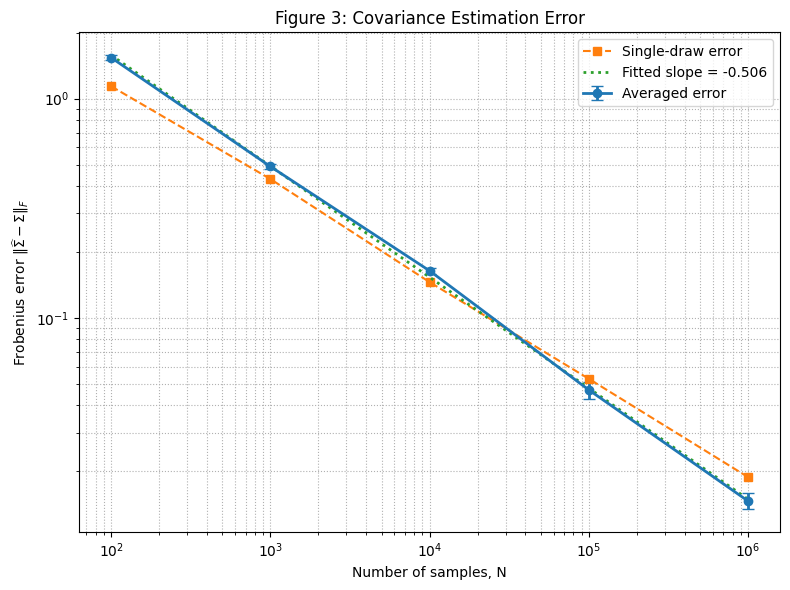

In [16]:
fig, axis = plt.subplots(
    figsize=(8, 6)
)

axis.errorbar(
    sample_sizes_step3,
    average_errors_step3,
    yerr=standard_errors_step3,
    fmt="o-",
    capsize=4,
    linewidth=2,
    label="Averaged error"
)

axis.loglog(
    sample_sizes_step3,
    single_draw_errors_step3,
    "s--",
    linewidth=1.5,
    label="Single-draw error"
)

axis.loglog(
    sample_sizes_step3,
    fitted_errors_step3,
    ":",
    linewidth=2,
    label=f"Fitted slope = {slope_step3:.3f}"
)

axis.set_title(
    "Figure 3: Covariance Estimation Error"
)

axis.set_xlabel("Number of samples, N")
axis.set_ylabel(
    r"Frobenius error "
    r"$\|\widehat{\Sigma}-\Sigma\|_F$"
)

axis.grid(
    True,
    which="both",
    linestyle=":"
)

axis.legend()
fig.tight_layout()
plt.show()

## Figure 3 Interpretation

The averaged error decreases as the number of samples increases. The fitted slope should be close to \(-0.5\), which agrees with an error that decreases approximately like \(1/\sqrt{N}\).

The averaged curve is more useful than the single-draw curve because averaging reduces the random fluctuations from individual simulations. The quantity \(\sqrt{N}\) times the averaged error should stay roughly constant if the expected \(1/\sqrt{N}\) relationship is correct.

## Number of Covariance Parameters

A symmetric \(d\times d\) covariance matrix has

$$
\frac{d(d+1)}{2}
$$

unique parameters because the entries above and below the diagonal are the same.

In [17]:
dimension_4 = 4
dimension_100 = 100

parameters_4 = dimension_4 * (dimension_4 + 1) // 2
parameters_100 = dimension_100 * (dimension_100 + 1) // 2

reference_sample_size = 10**4

estimated_sample_size_100 = (
    reference_sample_size
    * parameters_100
    / parameters_4
)

print(
    f"Free parameters for d={dimension_4}: "
    f"{parameters_4}"
)

print(
    f"Free parameters for d={dimension_100}: "
    f"{parameters_100}"
)

print(
    f"Approximate samples needed for d={dimension_100} "
    f"to match the relative accuracy at N={reference_sample_size:,}: "
    f"{estimated_sample_size_100:,.0f}"
)

Free parameters for d=4: 10
Free parameters for d=100: 5050
Approximate samples needed for d=100 to match the relative accuracy at N=10,000: 5,050,000


A radar with many array elements has a large covariance matrix with many unique entries. If there are not enough measurements, the estimated covariance matrix can be noisy and lead to poor beamforming or detection performance.

One possible solution is to collect more measurements. Another option is to use shrinkage or diagonal loading so that the covariance estimate is more stable.

# Step 4 — Linear transformations of random vectors

In Step 3 we estimated the covariance of a random vector. Here we use that covariance to predict what happens when we mix its coordinates. The handwritten Lecture 11 (pp. 2–3) writes the covariance as $C_X$. In the project notation, $C_X=\Sigma_x=\mathbb E[(X-\mu_x)(X-\mu_x)^T]$. The diagonal entries are variances and the off-diagonal entries are covariances.

For $Y=AX+b$, linearity of expectation gives
$$
\mu_y=\mathbb E[AX+b]=A\mathbb E[X]+b=A\mu_x+b.
$$
Subtracting the new mean shows why the offset $b$ moves the center without changing how the samples spread around it.
$$
\begin{aligned}
Y-\mu_y &= AX+b-(A\mu_x+b)=A(X-\mu_x),\\
\Sigma_y &= \mathbb E[(Y-\mu_y)(Y-\mu_y)^T]
 = \mathbb E[A(X-\mu_x)(X-\mu_x)^TA^T],\\
&= A\,\mathbb E[(X-\mu_x)(X-\mu_x)^T]\,A^T
 = A\Sigma_xA^T.
\end{aligned}
$$

### Case 1 — From two coordinates to three

Use $b=0$, $\mu_x=[1,-2]^T$, and $\Sigma_x=\begin{bmatrix}4&2\\2&4\end{bmatrix}$. With $A=\begin{bmatrix}1&2\\0&1\\1&-1\end{bmatrix}$,
$$
\mu_y=\begin{bmatrix}1+2(-2)\\-2\\1-(-2)\end{bmatrix}
=\begin{bmatrix}-3\\-2\\3\end{bmatrix},\qquad
\Sigma_y=
\underbrace{\begin{bmatrix}8&10\\2&4\\2&-2\end{bmatrix}}_{A\Sigma_x}
\underbrace{\begin{bmatrix}1&0&1\\2&1&-1\end{bmatrix}}_{A^T}
=\begin{bmatrix}28&10&-2\\10&4&-2\\-2&-2&4\end{bmatrix}.
$$

We can check an off-diagonal entry directly. Since $Y_1=X_1+2X_2$ and $Y_2=X_2$,
$$
\operatorname{Cov}(Y_1,Y_2)
=\operatorname{Cov}(X_1,X_2)+2\operatorname{Var}(X_2)=2+2(4)=10.
$$
The two independent columns of $A$ give two directions of variation, so the covariance has rank two. Since $Y_3=X_1-X_2$, every sample satisfies $y_1-3y_2-y_3=0$, the equation of a plane.

### Case 2 — From two coordinates to one direction

The second row of $A=\begin{bmatrix}1&1\\2&2\end{bmatrix}$ doubles the first, so $Y_2=2Y_1$. All the output variation is along the line $y_2=2y_1$.
$$
\mu_y=\begin{bmatrix}1-2\\2(1-2)\end{bmatrix}
=\begin{bmatrix}-1\\-2\end{bmatrix},\qquad
\Sigma_y=
\underbrace{\begin{bmatrix}6&6\\12&12\end{bmatrix}}_{A\Sigma_x}
\underbrace{\begin{bmatrix}1&2\\1&2\end{bmatrix}}_{A^T}
=\begin{bmatrix}12&24\\24&48\end{bmatrix}.
$$
The second covariance row also doubles the first, which gives rank one. Both cases have a singular covariance. The ordinary Gaussian PDF over the full output space would require an inverse of that covariance and division by the square root of its zero determinant.

### Comparing the simulation to the hand calculation

We generate samples with the given input mean and covariance and transform each sample with the same $A$ used above. The sample mean for coordinate $i$ has standard error $\sqrt{(\Sigma_y)_{ii}/N}$. For Gaussian samples, the unbiased sample covariance entry $(i,j)$ has standard error $\sqrt{\big((\Sigma_y)_{ii}(\Sigma_y)_{jj}+(\Sigma_y)_{ij}^2\big)/(N-1)}$. Dividing the absolute error by its standard error puts mean and covariance discrepancies on a comparable scale.

Samples per case: 1,000,000

Case 1: 3D plane
Hand mean: [-3 -2  3]
Sample mean: [-2.99814347 -1.99929134  2.99973055]
Mean difference: [ 0.00185653  0.00070866 -0.00026945]
Mean standard errors: [0.0052915 0.002     0.002    ]
Largest mean difference in standard errors: 0.354
Hand covariance:
[[28 10 -2]
 [10  4 -2]
 [-2 -2  4]]
Sample covariance:
[[27.97662639  9.99561553 -2.01022019]
 [ 9.99561553  3.99869609 -2.00047276]
 [-2.01022019 -2.00047276  3.99119808]]
Covariance difference:
[[-0.02337361 -0.00438447 -0.01022019]
 [-0.00438447 -0.00130391 -0.00047276]
 [-0.01022019 -0.00047276 -0.00880192]]
Covariance standard errors:
[[0.039598   0.01456023 0.01077033]
 [0.01456023 0.00565686 0.00447214]
 [0.01077033 0.00447214 0.00565686]]
Largest covariance difference in standard errors: 1.556
Largest formula-vs-hand mismatch: 0.0e+00
Covariance rank: 2
Covariance determinant: 1.599e-14

Case 2: 2D line
Hand mean: [-1 -2]
Sample mean: [-0.99885213 -1.99770426]
Mean difference: [0.0011478

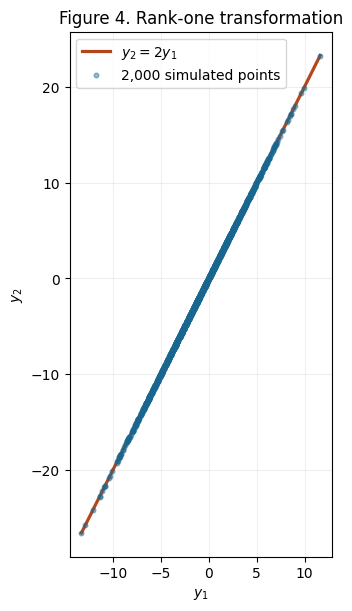

In [18]:
def gaussian_covariance_se(covariance, sample_count):
    '''Return the standard error of each sample covariance entry.'''
    variances = np.diag(covariance)
    return np.sqrt(
        (np.outer(variances, variances) + covariance**2) / (sample_count - 1)
    )


mu_step4 = np.array([1.0, -2.0])
Sigma_step4 = np.array([[4.0, 2.0], [2.0, 4.0]])
n_step4 = 10**6
samples_step4 = rng_step4.multivariate_normal(mu_step4, Sigma_step4, n_step4)

step4_cases = [
    (
        "Case 1: 3D plane",
        np.array([[1, 2], [0, 1], [1, -1]]),
        np.array([-3, -2, 3]),
        np.array([[28, 10, -2], [10, 4, -2], [-2, -2, 4]]),
    ),
    (
        "Case 2: 2D line",
        np.array([[1, 1], [2, 2]]),
        np.array([-1, -2]),
        np.array([[12, 24], [24, 48]]),
    ),
]

print(f"Samples per case: {n_step4:,}")
for case_name, A_step4, hand_mean, hand_covariance in step4_cases:
    # Each sample is a row, so x transforms with A.T on the right.
    transformed_step4 = samples_step4 @ A_step4.T
    computed_mean = A_step4 @ mu_step4
    computed_covariance = A_step4 @ Sigma_step4 @ A_step4.T
    sample_mean, sample_covariance = sample_mean_cov(transformed_step4)
    mean_se = np.sqrt(np.diag(hand_covariance) / n_step4)
    covariance_se = gaussian_covariance_se(hand_covariance, n_step4)
    mean_difference = sample_mean - hand_mean
    covariance_difference = sample_covariance - hand_covariance

    print(f"\n{case_name}")
    print(f"Hand mean: {hand_mean}")
    print(f"Sample mean: {sample_mean}")
    print(f"Mean difference: {mean_difference}")
    print(f"Mean standard errors: {mean_se}")
    print(f"Largest mean difference in standard errors: {np.max(abs(mean_difference) / mean_se):.3f}")
    print(f"Hand covariance:\n{hand_covariance}")
    print(f"Sample covariance:\n{sample_covariance}")
    print(f"Covariance difference:\n{covariance_difference}")
    print(f"Covariance standard errors:\n{covariance_se}")
    print(f"Largest covariance difference in standard errors: "
          f"{np.max(abs(covariance_difference) / covariance_se):.3f}")
    print(f"Largest formula-vs-hand mismatch: "
          f"{max(np.max(abs(computed_mean - hand_mean)), np.max(abs(computed_covariance - hand_covariance))):.1e}")
    print(f"Covariance rank: {np.linalg.matrix_rank(computed_covariance)}")
    print(f"Covariance determinant: {np.linalg.det(computed_covariance):.3e}")

line_samples_step4 = transformed_step4[:2000]
line_x_step4 = np.linspace(line_samples_step4[:, 0].min(), line_samples_step4[:, 0].max(), 150)
print(f"\nLargest |y2 - 2y1| in the rank-one sample: "
      f"{np.max(abs(transformed_step4[:, 1] - 2 * transformed_step4[:, 0])):.2e}")

fig, axis = plt.subplots(figsize=(7, 6), layout="constrained")
axis.plot(line_x_step4, 2 * line_x_step4, color="#b34719", linewidth=2.3, label=r"$y_2=2y_1$")
axis.scatter(
    *line_samples_step4.T, s=11, color="#186791", alpha=0.45,
    label=f"{len(line_samples_step4):,} simulated points", zorder=3,
)
axis.set(title="Figure 4. Rank-one transformation", xlabel=r"$y_1$", ylabel=r"$y_2$")
axis.set_aspect("equal", adjustable="box")
axis.grid(alpha=0.2)
axis.legend()
plt.show()

**Figure 4.** The line goes through the samples because the second output is twice the first for every draw. This is the perfect positive-correlation case from Lecture 9 (pp. 19–20). The reported maximum of $|y_2-2y_1|$ checks this across the full sample, including the points left out of the plot.

The rank calculation agrees with the geometry in both cases. A tiny nonzero determinant for the plane is floating-point roundoff around the exact value of zero. The largest sample covariance discrepancy is within two standard errors in each case, which is consistent with estimating the entries from a finite sample.

# Step 5 — The multivariate Gaussian

The scalar Gaussian from class uses the squared distance $(x-\mu)^2/\sigma^2$ in its exponent. For a $d$-dimensional vector, the covariance tells us how to measure that distance when the coordinates can move together. Using the density from handwritten Lecture 11 (p. 1),
$$
f_X(x)=\frac{1}{(2\pi)^{d/2}\sqrt{\det\Sigma}}\,
\exp\!\left[-\frac12\underbrace{(x-\mu)^T\Sigma^{-1}(x-\mu)}_{D^2}\right].
$$
Here $x$ is a point where we evaluate the PDF, $\mu$ is the mean vector, and $\Sigma$ is the positive definite covariance matrix. The factor involving $d$ and $\det\Sigma$ normalizes the density so its total integral is one. The exponent uses the squared Mahalanobis distance $D^2$. Along a direction with more spread, we can move farther from the mean before the density drops to the same level.

We use a Cholesky factor $L$ with $\Sigma=LL^T$. Taking determinants gives $\sqrt{\det\Sigma}=\prod_i L_{ii}$ since $L$ is triangular with positive diagonal entries. With $\delta=x-\mu$, the exponent simplifies to
$$
D^2=\delta^T(LL^T)^{-1}\delta
=(L^{-1}\delta)^T(L^{-1}\delta)=z^Tz.
$$
In the code, we get $z$ by solving $Lz=\delta$ directly. We check our formula against SciPy at five points, then integrate it to check the total mass.

Each marginal in this example has standard deviation $2$. Integrating on $[-16,16]^2$ includes eight standard deviations in each direction. For a standard normal $Z$, the mass outside the square is at most $4\Pr(Z>8)$, found by adding the bounds for the two tails of each coordinate.

In [19]:
from scipy.stats import norm

mu_step5 = np.zeros(2)
Sigma_step5 = np.array([[4.0, 2.0], [2.0, 4.0]])
probe_points_step5 = np.array([[-3.0, 1.0], [0.2, -0.4], [1.0, 3.0], [2.5, -1.2], [5.0, 4.0]])
own_pdf_step5 = gaussian_pdf(probe_points_step5, mu_step5, Sigma_step5)
scipy_pdf_step5 = multivariate_normal.pdf(probe_points_step5, mean=mu_step5, cov=Sigma_step5)
relative_difference_step5 = abs(own_pdf_step5 - scipy_pdf_step5) / scipy_pdf_step5

print(f"rho = {Sigma_step5[0, 1] / np.sqrt(Sigma_step5[0, 0] * Sigma_step5[1, 1]):.3f}")
print(f"det(Sigma) = {np.linalg.det(Sigma_step5):.6f}")
print("Point           Our PDF       SciPy PDF     Relative difference")
for point, own_value, reference_value, difference in zip(
    probe_points_step5, own_pdf_step5, scipy_pdf_step5, relative_difference_step5
):
    print(f"({point[0]:4.1f}, {point[1]:4.1f})  {own_value:.8f}    {reference_value:.8f}    {difference:.2e}")
print(f"Largest relative difference: {relative_difference_step5.max():.3e}")

integration_limit_step5 = 8 * np.sqrt(Sigma_step5[0, 0])
area_step5, quadrature_error_step5 = integrate.dblquad(
    lambda y, x: float(gaussian_pdf([x, y], mu_step5, Sigma_step5)),
    -integration_limit_step5, integration_limit_step5,
    -integration_limit_step5, integration_limit_step5,
    epsabs=1e-10, epsrel=1e-10,
)
print(f"\nIntegral over [-{integration_limit_step5:g}, {integration_limit_step5:g}] squared: {area_step5:.12f}")
print(f"Absolute difference from 1: {abs(area_step5 - 1):.3e}")
print(f"Quadrature error estimate: {quadrature_error_step5:.3e}")
print(f"Upper bound on probability outside the square: {4 * norm.sf(8):.3e}")

rho = 0.500
det(Sigma) = 12.000000
Point           Our PDF       SciPy PDF     Relative difference
(-3.0,  1.0)  0.00526330    0.00526330    8.24e-16
( 0.2, -0.4)  0.04384928    0.04384928    0.00e+00
( 1.0,  3.0)  0.01430713    0.01430713    8.49e-16
( 2.5, -1.2)  0.00773502    0.00773502    8.97e-16
( 5.0,  4.0)  0.00138739    0.00138739    0.00e+00
Largest relative difference: 8.971e-16



Integral over [-16, 16] squared: 1.000000000000
Absolute difference from 1: 2.220e-15
Quadrature error estimate: 6.125e-11
Upper bound on probability outside the square: 2.488e-15


### From a density level to a probability contour

The five pointwise differences from SciPy are at floating-point roundoff in this run. The integral over the square is one to the displayed precision, which is consistent with the small probability in the tails outside it.

Lecture 9 treats the probability of a region as the integral of the joint PDF over that region. Here we want the region inside an ellipse. In the standardized coordinates $z=L^{-1}(x-\mu)$, the ellipse $D^2\le q$ becomes the circle $z_1^2+z_2^2\le q$. The covariance of $Z$ is $L^{-1}\Sigma(L^{-1})^T=I$. Since this is still a jointly Gaussian vector, its two coordinates are independent standard normals. Their joint density at radius $r$ is $(2\pi)^{-1}e^{-r^2/2}$. In polar coordinates the area element adds a factor of $r$, and integrating over the angle cancels the $2\pi$. Therefore the probability inside the circle is
$$
p=\int_0^{\sqrt q} e^{-r^2/2}r\,dr=1-e^{-q/2}.
$$
Solving gives $q=-2\ln(1-p)$. The corresponding boundary is the contour where $f_X(x)=f_X(\mu)e^{-q/2}$. We count the simulated points satisfying $D^2\le q$ to check the probability label.

For a unit eigenvector $v$ of $\Sigma$ with eigenvalue $\lambda$, a displacement $\ell v$ from the mean gives $D^2=\ell^2/\lambda$. Setting this equal to $q$ gives the semiaxis length $\sqrt{q\lambda}$, and the full axis length is twice that. The long axis is along $x_2=x_1$ and the short axis is along $x_2=-x_1$.

In [20]:
probabilities_step5 = np.array([0.50, 0.90, 0.99])
radius_squared_step5 = -2 * np.log1p(-probabilities_step5)
n_step5 = 10_000
samples_step5 = rng_step5.multivariate_normal(mu_step5, Sigma_step5, size=n_step5)

centered_step5 = samples_step5 - mu_step5
solved_step5 = np.linalg.solve(Sigma_step5, centered_step5.T).T
distances_step5 = np.sum(centered_step5 * solved_step5, axis=1)
counts_step5 = np.count_nonzero(distances_step5[:, None] <= radius_squared_step5, axis=0)
fractions_step5 = counts_step5 / n_step5
fraction_se_step5 = np.sqrt(probabilities_step5 * (1 - probabilities_step5) / n_step5)

print(f"Sample count: {n_step5:,}")
print("Target   D^2       Count     Observed    Difference    Std. error")
for probability, radius_squared, count, fraction, se in zip(
    probabilities_step5, radius_squared_step5, counts_step5, fractions_step5, fraction_se_step5
):
    print(f"{probability:6.0%}   {radius_squared:7.4f}   {count:5,d}     "
          f"{fraction:8.4%}    {fraction - probability:+10.4%}    {se:10.4%}")

eigenvalues_step5 = np.linalg.eigvalsh(Sigma_step5)
print(f"\nOne-standard-deviation semiaxes (short, long): {np.sqrt(eigenvalues_step5)}")
print("Axis directions (short, long): -45 and +45 degrees")
for probability, radius_squared in zip(probabilities_step5, radius_squared_step5):
    full_lengths = 2 * np.sqrt(radius_squared * eigenvalues_step5)
    print(f"{probability:.0%} full axis lengths (short, long): {np.round(full_lengths, 4)}")

Sample count: 10,000
Target   D^2       Count     Observed    Difference    Std. error
   50%    1.3863   5,044     50.4400%      +0.4400%       0.5000%
   90%    4.6052   9,044     90.4400%      +0.4400%       0.3000%
   99%    9.2103   9,906     99.0600%      +0.0600%       0.0995%

One-standard-deviation semiaxes (short, long): [1.41421356 2.44948974]
Axis directions (short, long): -45 and +45 degrees
50% full axis lengths (short, long): [3.3302 5.7681]
90% full axis lengths (short, long): [ 6.0697 10.513 ]
99% full axis lengths (short, long): [ 8.5839 14.8677]


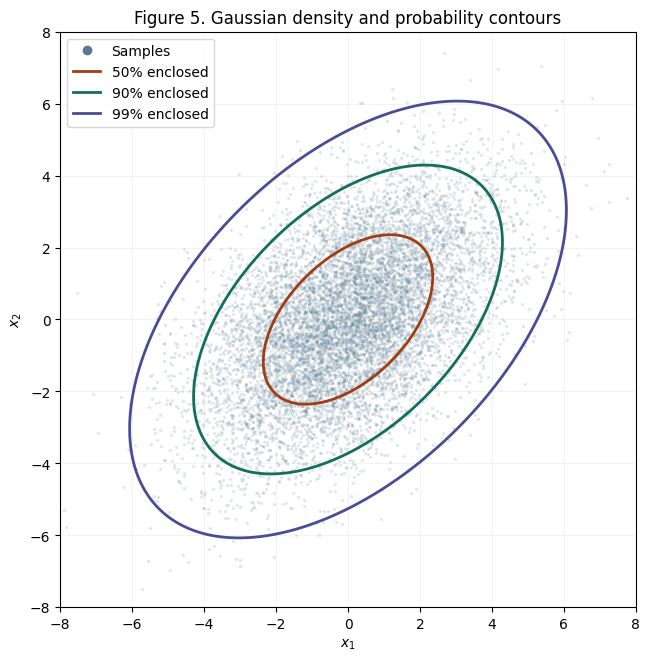

In [21]:
from matplotlib.lines import Line2D

grid_step5 = np.linspace(-8, 8, 501)
grid_x_step5, grid_y_step5 = np.meshgrid(grid_step5, grid_step5)
grid_points_step5 = np.stack((grid_x_step5, grid_y_step5), axis=-1)
colors_step5 = ["#a13c15", "#136e5b", "#4a4c95"]
sample_color = "#567a94"


def draw_probability_contours(axis, samples, covariance):
    '''Plot sample positions and the three constant-density boundaries.'''
    axis.scatter(*samples.T, s=5, color=sample_color, alpha=0.18, linewidths=0)
    peak = gaussian_pdf(mu_step5, mu_step5, covariance)
    density_levels = (peak * np.exp(-0.5 * radius_squared_step5))[::-1]
    axis.contour(
        grid_x_step5, grid_y_step5, gaussian_pdf(grid_points_step5, mu_step5, covariance),
        levels=density_levels, colors=colors_step5[::-1], linewidths=2,
    )
    axis.set(xlabel=r"$x_1$", ylabel=r"$x_2$", xlim=(-8, 8), ylim=(-8, 8))
    axis.set_aspect("equal", adjustable="box")
    axis.grid(alpha=0.15)


handles_step5 = [
    Line2D([], [], marker="o", linestyle="none", color=sample_color, label="Samples"),
    *[
        Line2D([], [], color=color, lw=2, label=f"{probability:.0%} enclosed")
        for probability, color in zip(probabilities_step5, colors_step5)
    ],
]

fig, axis = plt.subplots(figsize=(7, 6.5), layout="constrained")
draw_probability_contours(axis, samples_step5, Sigma_step5)
axis.set_title("Figure 5. Gaussian density and probability contours")
axis.legend(handles=handles_step5, loc="upper left")
plt.show()

**Figure 5.** The points spread farther along the positive diagonal because the two coordinates tend to increase and decrease together. For the 90% contour, 9,044 of the 10,000 draws landed inside. That is 90.44%, so the difference is 0.44 percentage points. A draw is either inside or outside, so the standard error of the fraction is $\sqrt{p(1-p)/N}$. The table gives 0.30 percentage points at $p=0.90$, putting the result within two standard errors of the target.

Correlation   det(Sigma)   90% short semiaxis   90% long semiaxis


       0.00      16.0000               4.2919              4.2919
       0.50      12.0000               3.0349              5.2565
       0.90       3.0400               1.3572              5.9160
       0.99       0.3184               0.4292              6.0545


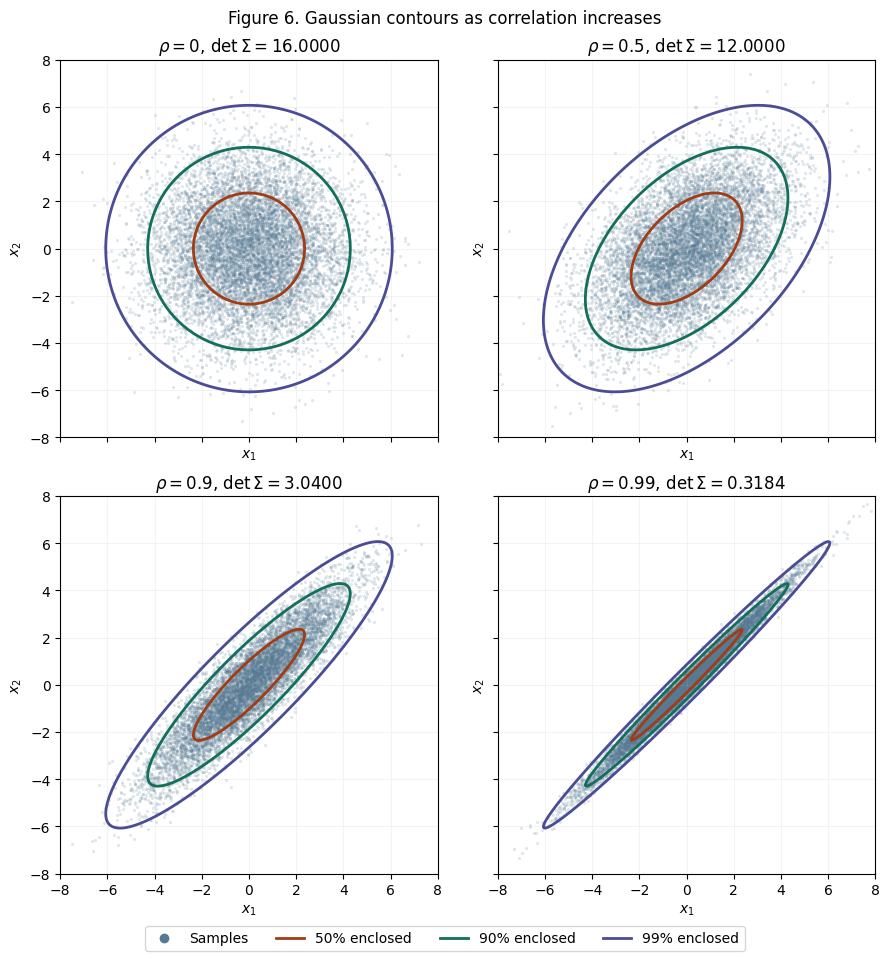

In [22]:
correlations_step5 = [0.0, 0.5, 0.9, 0.99]
fig, axes = plt.subplots(2, 2, figsize=(9, 9.5), sharex=True, sharey=True, layout="constrained")
fig.suptitle("Figure 6. Gaussian contours as correlation increases")
print("Correlation   det(Sigma)   90% short semiaxis   90% long semiaxis")
for axis, rho in zip(axes.flat, correlations_step5):
    covariance = 4 * np.array([[1, rho], [rho, 1]])
    samples = (
        samples_step5 if rho == 0.5
        else rng_step5.multivariate_normal(mu_step5, covariance, size=n_step5)
    )
    draw_probability_contours(axis, samples, covariance)
    semiaxes_90 = np.sqrt(radius_squared_step5[1] * np.linalg.eigvalsh(covariance))
    determinant = np.linalg.det(covariance)
    axis.set_title(rf"$\rho={rho:g}$, $\det\Sigma={determinant:.4f}$")
    print(f"{rho:11.2f}   {determinant:10.4f}   {semiaxes_90[0]:18.4f}   {semiaxes_90[1]:17.4f}")

fig.legend(handles=handles_step5, loc="outside lower center", ncol=4)
plt.show()

**Figure 6.** At $\rho=0$ the two axes have equal lengths. As $\rho$ increases the cloud narrows across the diagonal even though the individual variances stay at $4$. The determinant drops from $16$ at $\rho=0$ to $0.3184$ at $\rho=0.99$.

The narrowing makes sense if we look at the difference between the two measurements. Applying the variance-of-a-sum rule from Lecture 9 (p. 15) to $X_2+(-X_1)$ gives the variance of that difference. Since $\operatorname{Cov}(X_1,X_2)=4\rho$,
$$
\operatorname{Var}(X_2-X_1)=4+4-2(4\rho)=8(1-\rho).
$$
As $\rho$ approaches one, the difference has almost no spread. Knowing the first measurement then gives a close prediction of the second, so the second adds little information about how the pair varies.

# Step 6 — Decorrelation and whitening

Step 5 showed the directions where the cloud spreads the most and the least. Here we use those directions as the new axes. The handwritten Lecture 11 (pp. 7–10) writes the eigendecomposition as $C_X=UDU^T$. In the project notation it is $\Sigma=V\Lambda V^T$, where the columns of $V$ are unit eigenvectors and the diagonal of $\Lambda$ gives their variances.

The two original variances are equal and the covariance is positive. Taking the difference of the coordinates cancels some of their shared motion, while taking the sum reinforces it. Multiplying by $\Sigma$ confirms those directions and gives their eigenvalues.
$$
\Sigma\frac{1}{\sqrt{2}}\begin{bmatrix}1\\-1\end{bmatrix}
=2\frac{1}{\sqrt{2}}\begin{bmatrix}1\\-1\end{bmatrix},\qquad
\Sigma\frac{1}{\sqrt{2}}\begin{bmatrix}1\\1\end{bmatrix}
=6\frac{1}{\sqrt{2}}\begin{bmatrix}1\\1\end{bmatrix}.
$$
The code can return the negative of either vector. It still points along the same axis.

**Decorrelation.** Projecting onto the eigenvectors with $Y=V^T(X-\mu_x)$ expresses each sample in the new axes. Using the transformation rule from Step 4,
$$
\operatorname{Cov}(Y)=V^T\Sigma V=V^T(V\Lambda V^T)V=\Lambda.
$$
The new coordinates have zero covariance and variances $2$ and $6$. They are also independent because $Y$ is jointly Gaussian. With a diagonal covariance, the joint Gaussian PDF factors into its marginal PDFs, as shown in Lecture 11 (pp. 4–6). This is the Gaussian case we checked in Step 2.

**Whitening.** Lecture 11 relates the two vectors by $X=AZ+\mu_x$, with $Z$ standard normal and $AA^T=\Sigma$. Using $A=V\Lambda^{1/2}$, we solve that equation for $Z$.
$$
Z=A^{-1}(X-\mu_x)=\underbrace{\Lambda^{-1/2}V^T}_{W}(X-\mu_x),\qquad
\operatorname{Cov}(Z)=W\Sigma W^T=\Lambda^{-1/2}\Lambda\Lambda^{-1/2}=I.
$$
In the plot this means dividing each decorrelated coordinate by its own standard deviation. The input mean here is already zero. An extra orthogonal rotation $Q$ preserves the result since $(QW)\Sigma(QW)^T=QIQ^T=I$. This lets us choose the orientation of the whitened axes while keeping unit variances and zero covariances.

In [23]:
def report_covariance_check(label, transformed_samples, target_covariance):
    '''Compare a sample covariance to its theoretical value.'''
    _, estimate = sample_mean_cov(transformed_samples)
    difference = estimate - target_covariance
    standard_errors = gaussian_covariance_se(target_covariance, len(transformed_samples))
    print(f"\n{label} (N = {len(transformed_samples):,})")
    print(f"Sample covariance:\n{np.round(estimate, 6)}")
    print(f"Difference from theory:\n{np.round(difference, 6)}")
    print(f"Covariance standard errors:\n{np.round(standard_errors, 6)}")
    print(f"Frobenius error: {np.linalg.norm(difference, ord='fro'):.6f}")
    print(f"Largest entry error in standard errors: {np.max(abs(difference) / standard_errors):.3f}")


eigenvalues_step6, eigenvectors_step6 = np.linalg.eigh(Sigma_step5)
W_step6 = whitening_matrix(Sigma_step5)
identity_step6 = np.eye(Sigma_step5.shape[0])
# The input mean is zero. For row-wise samples, transpose the transform.
decorrelated_step6 = samples_step5 @ eigenvectors_step6
whitened_step6 = samples_step5 @ W_step6.T

print(f"Eigenvalues (short axis, long axis): {eigenvalues_step6}")
print(f"Eigenvectors (as columns):\n{eigenvectors_step6}")
print(f"Theoretical covariance after decorrelation:\n"
      f"{np.round(eigenvectors_step6.T @ Sigma_step5 @ eigenvectors_step6, 12)}")
print(f"Theoretical covariance after whitening:\n"
      f"{np.round(W_step6 @ Sigma_step5 @ W_step6.T, 12)}")

report_covariance_check("Decorrelated 2D samples", decorrelated_step6, np.diag(eigenvalues_step6))
report_covariance_check("Whitened 2D samples", whitened_step6, identity_step6)

theta_step6 = np.deg2rad(30)
Q_step6 = np.array([
    [np.cos(theta_step6), -np.sin(theta_step6)],
    [np.sin(theta_step6), np.cos(theta_step6)],
])
rotated_W_step6 = Q_step6 @ W_step6
rotation_error_step6 = np.linalg.norm(Q_step6 @ Q_step6.T - identity_step6, ord="fro")
rotated_identity_error_step6 = np.linalg.norm(
    rotated_W_step6 @ Sigma_step5 @ rotated_W_step6.T - identity_step6, ord="fro"
)
print(f"\n30-degree rotation orthogonality error: {rotation_error_step6:.3e}")
print(f"Rotated whitening error from the identity (theory): {rotated_identity_error_step6:.3e}")
report_covariance_check("Rotated, whitened 2D samples", samples_step5 @ rotated_W_step6.T, identity_step6)

W_step6_4d = whitening_matrix(Sigma_step3)
identity_step6_4d = np.eye(Sigma_step3.shape[0])
identity_error_step6_4d = np.linalg.norm(
    W_step6_4d @ Sigma_step3 @ W_step6_4d.T - identity_step6_4d, ord="fro"
)
samples_step6_4d = rng_step6.multivariate_normal(mu_step3, Sigma_step3, size=100_000)
whitened_step6_4d = (samples_step6_4d - mu_step3) @ W_step6_4d.T
print(f"\n4D whitening error from the identity (theory): {identity_error_step6_4d:.3e}")
report_covariance_check("Whitened 4D samples from the Step 3 covariance", whitened_step6_4d, identity_step6_4d)

Eigenvalues (short axis, long axis): [2. 6.]
Eigenvectors (as columns):
[[-0.70710678  0.70710678]
 [ 0.70710678  0.70710678]]
Theoretical covariance after decorrelation:
[[ 2.  0.]
 [-0.  6.]]
Theoretical covariance after whitening:
[[1. 0.]
 [0. 1.]]

Decorrelated 2D samples (N = 10,000)
Sample covariance:
[[ 1.957334 -0.049107]
 [-0.049107  5.927451]]
Difference from theory:
[[-0.042666 -0.049107]
 [-0.049107 -0.072549]]
Covariance standard errors:
[[0.028286 0.034643]
 [0.034643 0.084857]]
Frobenius error: 0.109118
Largest entry error in standard errors: 1.508

Whitened 2D samples (N = 10,000)
Sample covariance:
[[ 0.978667 -0.014176]
 [-0.014176  0.987909]]
Difference from theory:
[[-0.021333 -0.014176]
 [-0.014176 -0.012091]]
Covariance standard errors:
[[0.014143 0.010001]
 [0.010001 0.014143]]
Frobenius error: 0.031674
Largest entry error in standard errors: 1.508

30-degree rotation orthogonality error: 1.052e-17
Rotated whitening error from the identity (theory): 1.870e-16

R

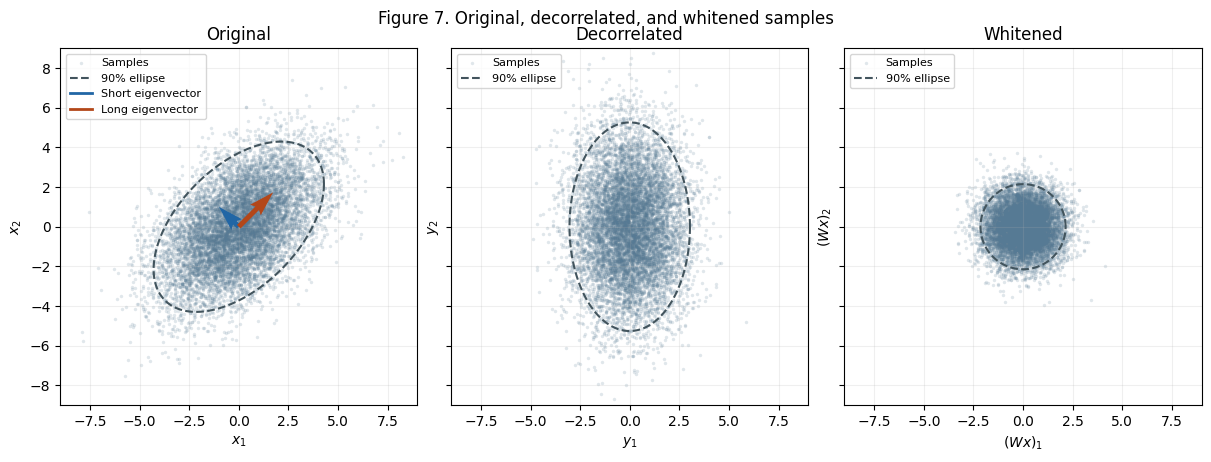

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), sharex=True, sharey=True, layout="constrained")
fig.suptitle("Figure 7. Original, decorrelated, and whitened samples")

panels_step6 = [
    (samples_step5, "Original", r"$x_1$", r"$x_2$"),
    (decorrelated_step6, "Decorrelated", r"$y_1$", r"$y_2$"),
    (whitened_step6, "Whitened", r"$(Wx)_1$", r"$(Wx)_2$"),
]
for axis, (sample_set, title, x_label, y_label) in zip(axes, panels_step6):
    axis.scatter(*sample_set.T, color=sample_color, s=6, alpha=0.18, linewidths=0, label="Samples")
    axis.set(title=title, xlabel=x_label, ylabel=y_label, xlim=(-9, 9), ylim=(-9, 9))
    axis.set_aspect("equal", adjustable="box")
    axis.grid(alpha=0.2)

# Show the same probability boundary for each theoretical covariance.
for axis, covariance in zip(axes, [Sigma_step5, np.diag(eigenvalues_step6), identity_step6]):
    ellipse_angles = np.linspace(0, 2 * np.pi, 240)
    circle_points = np.stack((np.cos(ellipse_angles), np.sin(ellipse_angles)))
    ellipse = np.sqrt(radius_squared_step5[1]) * np.linalg.cholesky(covariance) @ circle_points
    axis.plot(*ellipse, color="#42545d", ls="--", lw=1.5, label="90% ellipse")

arrow_colors_step6 = ["#2166a5", "#b34719"]
arrow_labels_step6 = ["Short eigenvector", "Long eigenvector"]
for value, direction, color, label in zip(
    eigenvalues_step6, eigenvectors_step6.T, arrow_colors_step6, arrow_labels_step6
):
    endpoint = np.sqrt(value) * direction
    axes[0].quiver(
        0, 0, *endpoint, angles="xy", scale_units="xy", scale=1,
        width=0.014, color=color, zorder=5,
    )
    axes[0].plot([], [], color=color, lw=2, label=label)

for axis in axes:
    axis.legend(loc="upper left", fontsize=8)

plt.show()

**Figure 7.** On the left, the eigenvector arrows follow the short and long axes of the tilted ellipse. In the middle, the same cloud is aligned with the plot axes and still spreads farther along the direction with eigenvalue $6$. On the right, the predicted contour is a circle because both variances are now one.

The covariance table lets us check what the plot shows. The decorrelated sample variances are close to $2$ and $6$, and the cross term is close to zero on the scale of its standard error. After whitening, both diagonal entries are close to one. The reported Frobenius error combines all entries of the difference from $I$. The additional rotation and the 4D check both give $I$ to floating-point precision in the matrix calculation. Their sample covariances still fluctuate, with the largest entrywise errors within two standard errors.

# Step 7 — The conditional Gaussian

Step 6 rotated the cloud until its coordinates stopped moving together. Here we keep the original coordinates and ask the estimation question directly: once we observe $X=x$, what is left to know about $Y$? We use the zero-mean pair from Steps 5 and 6, $\Sigma=\begin{bmatrix}4&2\\2&4\end{bmatrix}$, so $\sigma_X^2=\sigma_Y^2=4$, $\operatorname{Cov}(X,Y)=2$ and $\rho=0.5$.

### 7.1 Conditional density of $Y$ given $X=x$

From Step 5, $\det\Sigma=12$ and $\Sigma^{-1}=\frac{1}{12}\begin{bmatrix}4&-2\\-2&4\end{bmatrix}$. The joint density and the marginal of $X\sim\mathcal N(0,4)$ are
$$
f_{XY}(x,y)=\frac{1}{2\pi\sqrt{12}}\exp\!\left[-\frac{4x^2-4xy+4y^2}{2\cdot12}\right]
=\frac{1}{2\pi\sqrt{12}}\exp\!\left[-\frac{x^2-xy+y^2}{6}\right],
\qquad
f_X(x)=\frac{1}{\sqrt{2\pi\cdot4}}\,e^{-x^2/8}.
$$
As in Step 1, the conditional density is the ratio of the joint density to the marginal:
$$
f_{Y\mid X}(y\mid x)=\frac{f_{XY}(x,y)}{f_X(x)}
=\frac{\sqrt{8\pi}}{2\pi\sqrt{12}}\exp\!\left[-\frac{x^2-xy+y^2}{6}+\frac{x^2}{8}\right].
$$
Completing the square in $y$ gives $y^2-xy+x^2=\left(y-\tfrac{x}{2}\right)^2+\tfrac34x^2$, so the exponent becomes
$$
-\frac{\left(y-\tfrac{x}{2}\right)^2}{6}-\frac{3x^2}{24}+\frac{x^2}{8}
=-\frac{\left(y-\tfrac{x}{2}\right)^2}{2\cdot3}.
$$
The constant simplifies to $\dfrac{\sqrt{8\pi}}{2\pi\sqrt{12}}=\dfrac{2\sqrt{2\pi}}{4\pi\sqrt3}=\dfrac{1}{\sqrt{2\pi\cdot3}}$. Therefore
$$
f_{Y\mid X}(y\mid x)=\frac{1}{\sqrt{2\pi\cdot3}}\exp\!\left[-\frac{\left(y-\tfrac{x}{2}\right)^2}{2\cdot3}\right],
\qquad
Y\mid X=x\;\sim\;\mathcal N\!\left(\tfrac{x}{2},\,3\right).
$$
The terms in $x^2$ cancel exactly, which is why what remains is a Gaussian density in $y$. Its mean $\rho\,\frac{\sigma_Y}{\sigma_X}\,x=0.5x$ is a straight line in $x$, and its variance $\sigma_Y^2(1-\rho^2)=4(1-0.25)=3$ does not involve $x$ at all. For example, observing $x=4$, two standard deviations above the mean, moves the best guess for $Y$ from $0$ to $2$ and shrinks its standard deviation from $2$ to $\sqrt3\approx1.73$. The guess moves by one standard deviation of $Y$, not two. This is regression toward the mean.

### 7.2 The general partitioned result

Split a Gaussian vector into blocks $z_a$ and $z_b$:
$$
\begin{bmatrix}z_a\\ z_b\end{bmatrix}\sim\mathcal N\!\left(\begin{bmatrix}\mu_a\\ \mu_b\end{bmatrix},\begin{bmatrix}\Sigma_{aa}&\Sigma_{ab}\\ \Sigma_{ba}&\Sigma_{bb}\end{bmatrix}\right)
\;\Longrightarrow\;
z_a\mid z_b=b\;\sim\;\mathcal N\!\Big(\mu_a+\Sigma_{ab}\Sigma_{bb}^{-1}(b-\mu_b),\;\Sigma_{aa}-\Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}\Big).
$$
The conditional covariance is the Schur complement of $\Sigma_{bb}$. A short proof uses Steps 2 and 4. Define the prediction error $e=(z_a-\mu_a)-\Sigma_{ab}\Sigma_{bb}^{-1}(z_b-\mu_b)$. It is a linear function of the Gaussian vector, so $(e,z_b)$ is jointly Gaussian (Step 4), and
$$
\begin{aligned}
\operatorname{Cov}(e,z_b)&=\Sigma_{ab}-\Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{bb}=0,\\
\operatorname{Cov}(e)&=\Sigma_{aa}-\Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}-\Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}+\Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{bb}\Sigma_{bb}^{-1}\Sigma_{ba}
=\Sigma_{aa}-\Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}.
\end{aligned}
$$
Uncorrelated blocks of a Gaussian vector are independent (Step 2), so $e$ is independent of $z_b$. Writing $z_a=\mu_a+\Sigma_{ab}\Sigma_{bb}^{-1}(z_b-\mu_b)+e$ and fixing $z_b=b$ leaves a constant plus a Gaussian term that the conditioning does not touch, which gives the mean and covariance above.

For our pair take $z_a=Y$, $z_b=X$, $\mu=0$, $\Sigma_{aa}=\Sigma_{bb}=4$ and $\Sigma_{ab}=\Sigma_{ba}=2$:
$$
E[Y\mid X=x]=0+2\cdot\tfrac14\cdot x=0.5x,\qquad
\operatorname{Var}(Y\mid X=x)=4-2\cdot\tfrac14\cdot2=3.
$$
This is the two-dimensional answer from 7.1.

### 7.3 and 7.4 Numerical check by binning

We draw $10^6$ pairs with `rng_step7`, sort them into bins of width $h=0.2$ on $[-6,6]$, which is $\pm3\sigma_X$, and compute the mean and variance of $Y$ in each bin with vectorized `np.bincount` sums. Three details keep the comparison honest.

* Each bin mean is plotted and fitted against the average $x$ of the points in that bin, not the bin center. Because $E[Y\mid X]=0.5X$ exactly, the bin average satisfies $E[\bar y_k]=0.5\,\bar x_k$ with no binning bias. The density of $X$ is not flat across a bin, so the bin center would sit slightly off the bin's average $x$.
* The standard error of bin $k$'s mean is $s_k/\sqrt{n_k}$. We fit the line by weighted least squares with weights $1/\mathrm{SE}_k^2$, which gives the slope's standard error directly. The $\chi^2$ per degree of freedom of the weighted residuals checks that a straight line describes the bin means within their errors. A value near $1$ means no detectable curvature.
* A sample variance from $n$ Gaussian points has standard error $\sigma^2\sqrt{2/(n-1)}$. We use the pooled within-bin variance for $\sigma^2$ so that no bin's weight depends on its own noisy value. A bin also picks up a little spread because the conditional mean changes across its width. That extra spread is $0.5^2\operatorname{Var}(X\mid\text{bin})\approx0.25\,h^2/12$, and the code reports it.

In [25]:
n_step7 = 10**6
Sigma_step7 = np.array([[4.0, 2.0], [2.0, 4.0]])
# A Cholesky factor is unique, so these draws do not depend on the sign
# convention of the platform's SVD routine.
samples_step7 = rng_step7.multivariate_normal(
    np.zeros(2), Sigma_step7, size=n_step7, method="cholesky"
)
x_step7, y_step7 = samples_step7.T

# Partitioned-Gaussian result with z_a = Y and z_b = X.
slope_theory_step7 = Sigma_step7[1, 0] / Sigma_step7[0, 0]
variance_theory_step7 = Sigma_step7[1, 1] - Sigma_step7[1, 0] ** 2 / Sigma_step7[0, 0]

bin_width_step7 = 0.2
edges_step7 = np.linspace(-6.0, 6.0, 61)
n_bins_step7 = len(edges_step7) - 1
bin_step7 = np.digitize(x_step7, edges_step7) - 1
inside_step7 = (bin_step7 >= 0) & (bin_step7 < n_bins_step7)
index_step7 = bin_step7[inside_step7]
x_in_step7 = x_step7[inside_step7]
y_in_step7 = y_step7[inside_step7]

counts_step7 = np.bincount(index_step7, minlength=n_bins_step7)
x_bar_step7 = np.bincount(index_step7, weights=x_in_step7, minlength=n_bins_step7) / counts_step7
y_bar_step7 = np.bincount(index_step7, weights=y_in_step7, minlength=n_bins_step7) / counts_step7
# A second pass about each bin's own mean keeps the variances numerically stable.
y_var_step7 = np.bincount(
    index_step7, weights=(y_in_step7 - y_bar_step7[index_step7]) ** 2, minlength=n_bins_step7
) / (counts_step7 - 1)
x_var_step7 = np.bincount(
    index_step7, weights=(x_in_step7 - x_bar_step7[index_step7]) ** 2, minlength=n_bins_step7
) / (counts_step7 - 1)
mean_se_step7 = np.sqrt(y_var_step7 / counts_step7)


def weighted_line_fit(x, y, standard_errors):
    '''Fit y = b x + a by weighted least squares with known standard errors.'''
    coefficients, covariance = np.polyfit(x, y, 1, w=1 / standard_errors, cov="unscaled")
    residuals = (y - np.polyval(coefficients, x)) / standard_errors
    return coefficients, np.sqrt(np.diag(covariance)), np.sum(residuals**2) / (len(x) - 2)


(slope_step7, intercept_step7), (slope_se_step7, intercept_se_step7), chi2_mean_step7 = (
    weighted_line_fit(x_bar_step7, y_bar_step7, mean_se_step7)
)

within_dof_step7 = counts_step7 - 1
pooled_var_step7 = np.sum(within_dof_step7 * y_var_step7) / np.sum(within_dof_step7)
pooled_var_se_step7 = pooled_var_step7 * np.sqrt(2 / np.sum(within_dof_step7))
var_se_step7 = pooled_var_step7 * np.sqrt(2 / within_dof_step7)
(var_trend_step7, _), (var_trend_se_step7, _), _ = weighted_line_fit(
    x_bar_step7, y_var_step7, var_se_step7
)
chi2_var_step7 = np.sum(((y_var_step7 - pooled_var_step7) / var_se_step7) ** 2) / (n_bins_step7 - 1)
bin_spread_step7 = slope_theory_step7**2 * np.mean(x_var_step7)
unconditional_var_step7 = np.var(y_step7, ddof=1)
unconditional_var_se_step7 = Sigma_step7[1, 1] * np.sqrt(2 / (n_step7 - 1))

print(f"Samples: {n_step7:,}. Inside [-6, 6]: {counts_step7.sum():,} in {n_bins_step7} bins of width {bin_width_step7}")
print(f"Points per bin: {counts_step7.min():,} (outermost) to {counts_step7.max():,} (center)")

print("\nConditional mean: weighted fit of the bin means against the bin-average x")
print(f"  slope     = {slope_step7:.5f} ± {slope_se_step7:.5f}   theory {slope_theory_step7:.1f}   "
      f"difference {slope_step7 - slope_theory_step7:+.5f} = {(slope_step7 - slope_theory_step7) / slope_se_step7:+.2f} SE")
print(f"  intercept = {intercept_step7:+.5f} ± {intercept_se_step7:.5f}   theory 0     "
      f"difference {intercept_step7:+.5f} = {intercept_step7 / intercept_se_step7:+.2f} SE")
print(f"  chi^2 per degree of freedom about the line ({n_bins_step7 - 2} dof): {chi2_mean_step7:.3f}")

print("\nConditional variance")
print(f"  pooled within-bin variance = {pooled_var_step7:.5f} ± {pooled_var_se_step7:.5f}   theory {variance_theory_step7:.1f}   "
      f"difference {pooled_var_step7 - variance_theory_step7:+.5f} = {(pooled_var_step7 - variance_theory_step7) / pooled_var_se_step7:+.2f} SE")
print(f"  trend of the bin variances against x = {var_trend_step7:+.5f} ± {var_trend_se_step7:.5f} per unit x   theory 0   "
      f"= {var_trend_step7 / var_trend_se_step7:+.2f} SE")
print(f"  chi^2 per degree of freedom about a constant ({n_bins_step7 - 1} dof): {chi2_var_step7:.3f}")
print(f"  extra spread from the bin width, 0.25 * Var(X | bin): {bin_spread_step7:.5f}")
print(f"  theory: conditional standard deviation sqrt(3) = {np.sqrt(variance_theory_step7):.5f}, "
      f"unconditional standard deviation {np.sqrt(Sigma_step7[1, 1]):.1f}")
print(f"  unconditional Var(Y) = {unconditional_var_step7:.5f} ± {unconditional_var_se_step7:.5f}   theory {Sigma_step7[1, 1]:.1f}   "
      f"difference {unconditional_var_step7 - Sigma_step7[1, 1]:+.5f} = "
      f"{(unconditional_var_step7 - Sigma_step7[1, 1]) / unconditional_var_se_step7:+.2f} SE")

print("\nFive sample bins")
print("  bin-average x   mean of Y   0.5 x    (mean - 0.5 x) / SE   variance of Y   count")
for target in (-4.0, -2.0, 0.0, 2.0, 4.0):
    k = np.argmin(abs((edges_step7[:-1] + edges_step7[1:]) / 2 - (target + bin_width_step7 / 2)))
    print(f"  {x_bar_step7[k]:+13.4f}   {y_bar_step7[k]:+9.4f}   {slope_theory_step7 * x_bar_step7[k]:+7.4f}"
          f"   {(y_bar_step7[k] - slope_theory_step7 * x_bar_step7[k]) / mean_se_step7[k]:+19.2f}"
          f"   {y_var_step7[k]:13.4f}   {counts_step7[k]:6,d}")

Samples: 1,000,000. Inside [-6, 6]: 997,283 in 60 bins of width 0.2
Points per bin: 489 (outermost) to 39,724 (center)

Conditional mean: weighted fit of the bin means against the bin-average x
  slope     = 0.50119 ± 0.00088   theory 0.5   difference +0.00119 = +1.35 SE
  intercept = +0.00098 ± 0.00174   theory 0     difference +0.00098 = +0.56 SE
  chi^2 per degree of freedom about the line (58 dof): 0.883

Conditional variance
  pooled within-bin variance = 3.00735 ± 0.00426   theory 3.0   difference +0.00735 = +1.72 SE
  trend of the bin variances against x = -0.00213 ± 0.00216 per unit x   theory 0   = -0.99 SE
  chi^2 per degree of freedom about a constant (59 dof): 1.003
  extra spread from the bin width, 0.25 * Var(X | bin): 0.00083
  theory: conditional standard deviation sqrt(3) = 1.73205, unconditional standard deviation 2.0
  unconditional Var(Y) = 4.01126 ± 0.00566   theory 4.0   difference +0.01126 = +1.99 SE

Five sample bins
  bin-average x   mean of Y   0.5 x    (mean 

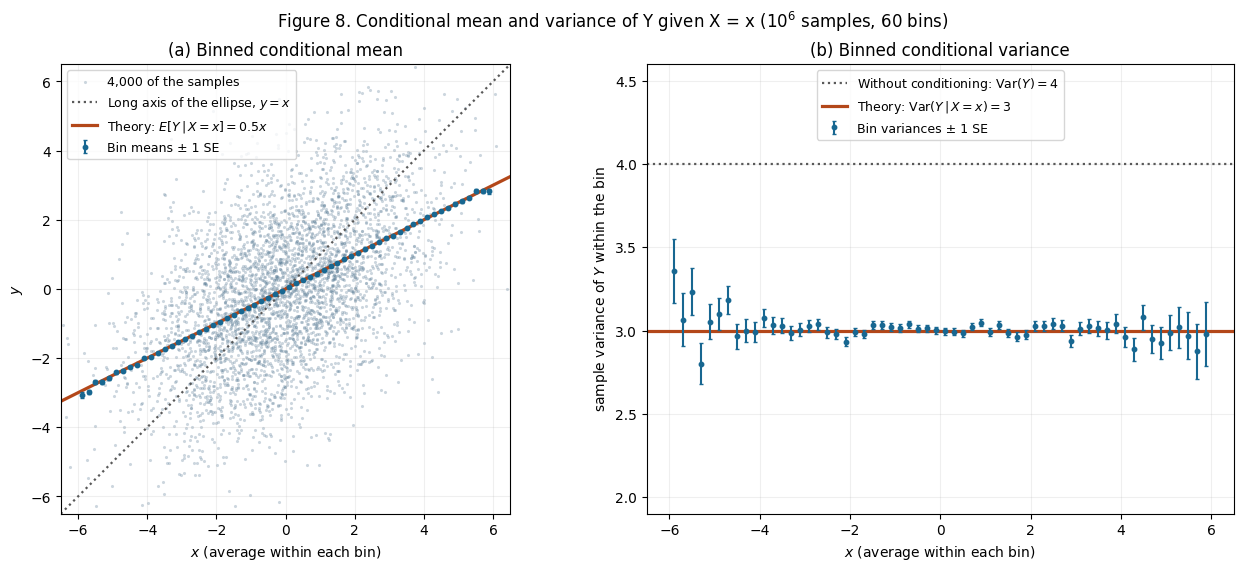

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6), layout="constrained")
fig.suptitle("Figure 8. Conditional mean and variance of Y given X = x (10$^6$ samples, 60 bins)")
line_x_step7 = np.array([-6.5, 6.5])

axis = axes[0]
axis.scatter(
    x_step7[:4000], y_step7[:4000], s=5, color=sample_color, alpha=0.3, linewidths=0,
    label="4,000 of the samples",
)
axis.plot(line_x_step7, line_x_step7, color="0.35", linestyle=":", linewidth=1.6,
          label=r"Long axis of the ellipse, $y=x$")
axis.plot(line_x_step7, slope_theory_step7 * line_x_step7, color="#b34719", linewidth=2.3,
          label=r"Theory: $E[Y\,|\,X=x]=0.5x$")
axis.errorbar(
    x_bar_step7, y_bar_step7, yerr=mean_se_step7, fmt="o", ms=3.2, color="#186791",
    capsize=1.5, label="Bin means ± 1 SE", zorder=3,
)
axis.set(title="(a) Binned conditional mean", xlabel=r"$x$ (average within each bin)",
         ylabel=r"$y$", xlim=(-6.5, 6.5), ylim=(-6.5, 6.5))
axis.set_aspect("equal", adjustable="box")
axis.grid(alpha=0.2)
axis.legend(loc="upper left", fontsize=9)

axis = axes[1]
axis.axhline(Sigma_step7[1, 1], color="0.35", linestyle=":", linewidth=1.6,
             label=r"Without conditioning: Var$(Y)=4$")
axis.axhline(variance_theory_step7, color="#b34719", linewidth=2.3,
             label=r"Theory: Var$(Y\,|\,X=x)=3$")
axis.errorbar(
    x_bar_step7, y_var_step7, yerr=var_se_step7, fmt="o", ms=3.2, color="#186791",
    capsize=1.5, label="Bin variances ± 1 SE", zorder=3,
)
axis.set(title="(b) Binned conditional variance", xlabel=r"$x$ (average within each bin)",
         ylabel=r"sample variance of $Y$ within the bin", xlim=(-6.5, 6.5), ylim=(1.9, 4.6))
axis.grid(alpha=0.2)
axis.legend(loc="upper center", fontsize=9, ncol=1)
plt.show()

**Figure 8.** In panel (a) the 60 bin means fall on the theoretical line $E[Y\mid X=x]=0.5x$ across the whole $\pm3\sigma_X$ range. The weighted fit gives a slope of $0.50119\pm0.00088$, which is 1.35 standard errors from $0.5$, and an intercept 0.56 standard errors from zero. The $\chi^2$ per degree of freedom about the line is 0.883 on 58 degrees of freedom, so a straight line describes the bin means within their errors and there is no sign of curvature. The conditional mean is also visibly flatter than the long axis of the ellipse, $y=x$, which is the Step 6 eigenvector direction. At $x=4$ the long axis would predict $4$, but the best guess for $Y$ is $2$. The gap between the two lines is regression toward the mean.

In panel (b) the bin variances scatter around $3$ with no trend. Their pooled value is $3.00735\pm0.00426$, which is 1.72 standard errors above $3$, and 0.00083 of that excess is the expected spread from the bin width. The fitted trend against $x$ is $-0.00213\pm0.00216$ per unit of $x$, which is 0.99 standard errors from zero. The $\chi^2$ per degree of freedom about a constant is 1.003 on 59 degrees of freedom, and that test would also catch a U-shaped dependence on $x$ that a linear trend would miss. The error bars widen toward the edges because the outermost bins hold only 489 points, against 39,724 at the center. The dotted line is the variance of $Y$ before we look at $X$, with a sample value of $4.01126\pm0.00566$ (1.99 standard errors above $4$). Observing $X$ removes the fraction $\rho^2=0.25$ of that variance, whichever value of $X$ we observe.

In [27]:
def conditional_moments_step7(x):
    '''Mean and variance of Y given X = x for Step 1's density f(x, y) = x + y.'''
    mass = integrate.quad(lambda y: float(joint_xy(x, y)), 0, 1)[0]
    first = integrate.quad(lambda y: y * float(joint_xy(x, y)), 0, 1)[0] / mass
    second = integrate.quad(lambda y: y**2 * float(joint_xy(x, y)), 0, 1)[0] / mass
    return first, second - first**2


print("Step 1 density f(x, y) = x + y on the unit square")
print("   x    E[Y | X = x]   Var(Y | X = x)")
step1_conditionals_step7 = {}
for x_value in (0.0, 0.5, 1.0):
    step1_conditionals_step7[x_value] = conditional_moments_step7(x_value)
    print(f"{x_value:4.1f}   {step1_conditionals_step7[x_value][0]:12.6f}   {step1_conditionals_step7[x_value][1]:14.6f}")
endpoint_average_step7 = (step1_conditionals_step7[0.0][0] + step1_conditionals_step7[1.0][0]) / 2
print(f"A linear conditional mean would give {endpoint_average_step7:.6f} at x = 0.5 "
      f"(the average of the end values). The actual value is {step1_conditionals_step7[0.5][0]:.6f}.")

# Step 2's pair: X uniform on (-1, 1) and Y = X^2. Fit the best linear (affine)
# predictor of Y from X with lmmse_weights on the centered sample covariance.
x_uniform_step7 = rng_step7.uniform(-1, 1, size=n_step7)
y_square_step7 = x_uniform_step7**2
pair_mean_step7, pair_cov_step7 = sample_mean_cov(np.column_stack([x_uniform_step7, y_square_step7]))
linear_weight_step7 = lmmse_weights(pair_cov_step7[:1, :1], pair_cov_step7[:1, 1])[0]
x_centered_step7 = x_uniform_step7 - pair_mean_step7[0]
linear_error_step7 = y_square_step7 - (pair_mean_step7[1] + linear_weight_step7 * x_centered_step7)
conditional_error_step7 = y_square_step7 - x_uniform_step7**2
# The residual's spread depends on x here, so the weight's standard error uses the
# heteroscedasticity-robust (sandwich) form.
linear_weight_se_step7 = np.sqrt(np.mean(x_centered_step7**2 * linear_error_step7**2)) / (
    np.sqrt(n_step7) * np.mean(x_centered_step7**2)
)
linear_mse_step7 = np.mean(linear_error_step7**2)
linear_mse_se_step7 = np.std(linear_error_step7**2, ddof=1) / np.sqrt(n_step7)
print(f"\nStep 2 pair, Y = X^2 with X ~ Uniform(-1, 1), {n_step7:,} samples")
print(f"  best linear predictor: weight on X = {linear_weight_step7:+.6f} ± {linear_weight_se_step7:.6f}   theory 0   "
      f"= {linear_weight_step7 / linear_weight_se_step7:+.2f} SE")
print(f"  its MSE = {linear_mse_step7:.6f} ± {linear_mse_se_step7:.6f}   theory Var(Y) = 4/45 = {4 / 45:.6f}   "
      f"difference {linear_mse_step7 - 4 / 45:+.6f} = {(linear_mse_step7 - 4 / 45) / linear_mse_se_step7:+.2f} SE")
print(f"  conditional mean E[Y | X] = X^2: MSE = {np.mean(conditional_error_step7**2):.1f}")

Step 1 density f(x, y) = x + y on the unit square
   x    E[Y | X = x]   Var(Y | X = x)
 0.0       0.666667         0.055556
 0.5       0.583333         0.076389
 1.0       0.555556         0.080247
A linear conditional mean would give 0.611111 at x = 0.5 (the average of the end values). The actual value is 0.583333.

Step 2 pair, Y = X^2 with X ~ Uniform(-1, 1), 1,000,000 samples
  best linear predictor: weight on X = -0.000815 ± 0.000648   theory 0   = -1.26 SE
  its MSE = 0.088737 ± 0.000095   theory Var(Y) = 4/45 = 0.088889   difference -0.000151 = -1.59 SE
  conditional mean E[Y | X] = X^2: MSE = 0.0


### 7.4 A constant conditional variance is special to the Gaussian

For a jointly Gaussian pair the conditional variance is the Schur complement $\Sigma_{aa}-\Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}$, which contains no $x$, so every vertical slice of the cloud in Figure 8a has the same spread. This is special to the Gaussian. Step 1's density $f(x,y)=x+y$ is a counterexample: the table above shows $\operatorname{Var}(Y\mid X=x)$ rising from 0.055556 at $x=0$ to 0.080247 at $x=1$. Its conditional mean is not linear either. The value at $x=0.5$ is 0.583333, below 0.611111, the average of the two end values.

### 7.5 Why linearity makes the linear estimator optimal

Adding and subtracting $E[S\mid X]$ splits the error of any estimator $g(X)$ as $E[(S-g(X))^2]=E[\operatorname{Var}(S\mid X)]+E\big[(E[S\mid X]-g(X))^2\big]$, so the best estimator of any form is the conditional mean $E[S\mid X]$. For jointly Gaussian data, 7.2 shows that this conditional mean is the linear function $\Sigma_{sx}^T\Sigma_{xx}^{-1}X$, so the best linear estimator of Step 8 is the best estimator outright: its error is the conditional variance, and no nonlinear processing can do better. Without Gaussianity a linear estimator is only convenient: for Step 2's $Y=X^2$, the best linear predictor gives $X$ a weight of $-0.000815\pm0.000648$ (theory $0$) and leaves an MSE of $0.088737\pm0.000095$ (theory $4/45=0.088889$, 1.59 standard errors away), while the conditional mean $X^2$ predicts $Y$ with zero error.

# Step 8 — Fusing two correlated sensors

A quantity $S\sim\mathcal N(0,\sigma_s^2)$ with $\sigma_s^2=4$ is read by two sensors, $X=S\mathbf 1+N$ with $\mathbf 1=[1,1]^T$. The noise $N=[N_1,N_2]^T$ has zero mean, is independent of $S$, and has covariance $\Sigma_N=\begin{bmatrix}1&c\\c&2\end{bmatrix}$. Sensor 1 is the better sensor. Steps 4 and 7 supply the two tools: the covariance of a linear map and the conditional Gaussian.

### 8.1 Second-order statistics

Because $E[S]=0$, $E[N]=0$ and $S$ is independent of $N$, we have $E[SN]=E[S]\,E[N]=0$, so every cross term vanishes:
$$
\begin{aligned}
\Sigma_{xx}&=E[XX^T]=E\big[(S\mathbf 1+N)(S\mathbf 1+N)^T\big]
=E[S^2]\,\mathbf 1\mathbf 1^T+\mathbf 1\,E[SN^T]+E[NS]\,\mathbf 1^T+E[NN^T]
=\sigma_s^2\mathbf 1\mathbf 1^T+\Sigma_N\\
&=\begin{bmatrix}\sigma_s^2+1&\sigma_s^2+c\\ \sigma_s^2+c&\sigma_s^2+2\end{bmatrix}
=\begin{bmatrix}5&4+c\\4+c&6\end{bmatrix},\\[6pt]
\Sigma_{sx}&=E[XS]=E\big[(S\mathbf 1+N)S\big]=E[S^2]\,\mathbf 1+E[NS]=\sigma_s^2\mathbf 1=\begin{bmatrix}4\\4\end{bmatrix}.
\end{aligned}
$$
This is the Step 4 rule $A\Sigma A^T$ with $X=\begin{bmatrix}\mathbf 1&I\end{bmatrix}\begin{bmatrix}S\\N\end{bmatrix}$ and the block-diagonal input covariance $\operatorname{diag}(\sigma_s^2,\Sigma_N)$. The shared signal adds $\sigma_s^2=4$ to every entry of $\Sigma_{xx}$, and the noise adds its own covariance on top.

### 8.2 The linear MMSE estimator

For $\hat S=w^TX$ the mean squared error is a quadratic in $w$:
$$
\begin{aligned}
J(w)=E\big[(S-w^TX)^2\big]&=E[S^2]-2w^TE[XS]+w^TE[XX^T]\,w=\sigma_s^2-2w^T\Sigma_{sx}+w^T\Sigma_{xx}w,\\
\nabla_wJ&=-2\Sigma_{sx}+2\Sigma_{xx}w=0
\;\Longrightarrow\;\Sigma_{xx}w=\Sigma_{sx}
\;\Longrightarrow\;w=\Sigma_{xx}^{-1}\Sigma_{sx}.
\end{aligned}
$$
The Hessian $2\Sigma_{xx}$ is positive definite, so this stationary point is the minimum. The condition $\Sigma_{xx}w=\Sigma_{sx}$ is the orthogonality principle $E[(S-w^TX)X]=0$: the error is uncorrelated with every measurement. Substituting $\Sigma_{xx}w=\Sigma_{sx}$ into $J$,
$$
\text{MMSE}=\sigma_s^2-2w^T\Sigma_{sx}+w^T\Sigma_{sx}=\sigma_s^2-w^T\Sigma_{sx}=\sigma_s^2-\Sigma_{sx}^T\Sigma_{xx}^{-1}\Sigma_{sx}.
$$
With $S$ and $N$ Gaussian, $(S,X)$ is jointly Gaussian, and this MMSE is exactly the conditional variance $\operatorname{Var}(S\mid X)$ from 7.2 with $z_a=S$ and $z_b=X$. `lmmse_weights` in `mp3lib.py` solves $\Sigma_{xx}w=\Sigma_{sx}$ with `np.linalg.solve` instead of forming $\Sigma_{xx}^{-1}$.

### 8.3 Admissible range of $c$

$\Sigma_N$ is symmetric for every $c$, so it is a valid covariance exactly when it is positive semidefinite. Its trace is $3$ and its determinant is $2-c^2$, so its eigenvalues are
$$
\lambda_\pm=\frac{3\pm\sqrt{9-4(2-c^2)}}{2}=\frac{3\pm\sqrt{1+4c^2}}{2}.
$$
$\lambda_+$ is always positive, and $\lambda_-\ge0$ exactly when $\sqrt{1+4c^2}\le3$, that is, when $c^2\le2$. Equivalently, the noise correlation coefficient $\rho_N=c/\sqrt{1\cdot2}$ must lie in $[-1,1]$. For $|c|<\sqrt2\approx1.41421$, $\Sigma_N$ is positive definite. At $|c|=\sqrt2$ it is singular: then $N_2=\pm\sqrt2\,N_1$ exactly and all of the noise lies on a line. We use the open range $|c|<\sqrt2$ and treat the endpoints as limits. The code below checks the boundary with `is_valid_covariance` from Step 3.

In [28]:
sigma_s2_step8 = 4.0
ones_step8 = np.ones(2)
c_limit_step8 = np.sqrt(2.0)


def noise_covariance_step8(c):
    return np.array([[1.0, c], [c, 2.0]])


def fusion_statistics_step8(c):
    '''Sigma_xx and Sigma_sx for X = S 1 + N, as derived in 8.1.'''
    Sigma_xx = sigma_s2_step8 * np.outer(ones_step8, ones_step8) + noise_covariance_step8(c)
    Sigma_sx = sigma_s2_step8 * ones_step8
    return Sigma_xx, Sigma_sx


def lmmse_solution_step8(c):
    '''LMMSE weights from mp3lib.lmmse_weights and the resulting MMSE.'''
    Sigma_xx, Sigma_sx = fusion_statistics_step8(c)
    weights = lmmse_weights(Sigma_xx, Sigma_sx)
    return weights, sigma_s2_step8 - Sigma_sx @ weights


print(f"Admissible range: |c| < sqrt(2) = {c_limit_step8:.5f}")
print("        c    eigenvalues of Sigma_N     det(Sigma_N)   is_valid_covariance")
for c in (-1.415, -1.414, 0.0, 1.414, c_limit_step8, 1.415):
    eigenvalues = np.linalg.eigvalsh(noise_covariance_step8(c))
    print(f"{c:+9.5f}   [{eigenvalues[0]:+.2e}, {eigenvalues[1]:.4f}]   "
          f"{np.linalg.det(noise_covariance_step8(c)):+.3e}   {is_valid_covariance(noise_covariance_step8(c))}")
print("At c = sqrt(2) the smallest eigenvalue is zero up to rounding, which is why is_valid_covariance has a tolerance.")

Sigma_xx_example_step8, Sigma_sx_example_step8 = fusion_statistics_step8(0.5)
print(f"\nExample, c = 0.5:\nSigma_xx =\n{Sigma_xx_example_step8}\nSigma_sx = {Sigma_sx_example_step8}")
for c in (0.0, 1.4, c_limit_step8):
    Sigma_xx, _ = fusion_statistics_step8(c)
    print(f"c = {c:.5f}: det(Sigma_xx) = {np.linalg.det(Sigma_xx):.4f}, "
          f"condition number = {np.linalg.cond(Sigma_xx):.1f}")

Admissible range: |c| < sqrt(2) = 1.41421
        c    eigenvalues of Sigma_N     det(Sigma_N)   is_valid_covariance
 -1.41500   [-7.41e-04, 3.0007]   -2.225e-03   False
 -1.41400   [+2.01e-04, 2.9998]   +6.040e-04   True
 +0.00000   [+1.00e+00, 2.0000]   +2.000e+00   True
 +1.41400   [+2.01e-04, 2.9998]   +6.040e-04   True
 +1.41421   [-1.11e-16, 3.0000]   -3.140e-16   True
 +1.41500   [-7.41e-04, 3.0007]   -2.225e-03   False
At c = sqrt(2) the smallest eigenvalue is zero up to rounding, which is why is_valid_covariance has a tolerance.

Example, c = 0.5:
Sigma_xx =
[[5.  4.5]
 [4.5 6. ]]
Sigma_sx = [4. 4.]
c = 0.00000: det(Sigma_xx) = 14.0000, condition number = 6.5
c = 1.40000: det(Sigma_xx) = 0.8400, condition number = 142.0
c = 1.41421: det(Sigma_xx) = 0.6863, condition number = 174.3


### 8.4 Weights and error across $c$, compared with two baselines

* **Best single sensor.** Using sensor $k$ alone with its own optimal weight $\sigma_s^2/(\sigma_s^2+\sigma_k^2)$ gives an MSE of $\sigma_s^2\sigma_k^2/(\sigma_s^2+\sigma_k^2)$. That is $4\cdot1/5=0.8$ for sensor 1 and $4\cdot2/6\approx1.333$ for sensor 2. A single sensor never sees the other sensor's noise, so this baseline is $0.8$ for every $c$.
* **Naive equal weighting.** Averaging the two readings, $\hat S=(X_1+X_2)/2$, leaves the error $(N_1+N_2)/2$. Its MSE is $\operatorname{Var}\big((N_1+N_2)/2\big)=(1+2+2c)/4=(3+2c)/4$, which depends on $c$ because positively correlated noise does not average out.

The table adds $c=0.8$ to the requested values because 8.9 checks that row by Monte Carlo.

In [29]:
c_table_step8 = np.array([-1.4, -1.0, -0.5, 0.0, 0.5, 0.8, 1.0, 1.2, 1.4])
single_sensor_mse_step8 = [sigma_s2_step8 * v / (sigma_s2_step8 + v) for v in (1.0, 2.0)]
best_single_step8 = min(single_sensor_mse_step8)
print(f"Single sensors with their own optimal weight: sensor 1 MSE = {single_sensor_mse_step8[0]:.6f}, "
      f"sensor 2 MSE = {single_sensor_mse_step8[1]:.6f}\n")

table_weights_step8 = np.empty((len(c_table_step8), 2))
table_mmse_step8 = np.empty(len(c_table_step8))
print(f"{'c':>6}{'w1':>11}{'w2':>11}{'LMMSE':>11}{'sensor 1 alone':>16}{'equal weights':>15}{'LMMSE change vs sensor 1':>26}")
for row, c in enumerate(c_table_step8):
    table_weights_step8[row], table_mmse_step8[row] = lmmse_solution_step8(c)
    equal_mse = (3 + 2 * c) / 4
    # Round before formatting so a rounding-level -1e-16 at c = 1 prints as 0.0%.
    change = round((table_mmse_step8[row] - best_single_step8) / best_single_step8, 6) + 0.0
    print(f"{c:+6.1f}{table_weights_step8[row, 0]:11.6f}{table_weights_step8[row, 1] + 0.0:+11.6f}"
          f"{table_mmse_step8[row]:11.6f}{best_single_step8:16.6f}{equal_mse:15.6f}{change:+25.1%}")

# Check-yourself values from the manual, rounded there to six decimals.
manual_step8 = {
    0.0: ([0.571429, 0.285714], 0.571429),
    0.8: ([0.689655, 0.114943], 0.781609),
    1.0: ([0.8, 0.0], 0.8),
    1.4: ([2.857143, -1.904762], 0.190476),
}
largest_manual_gap_step8 = max(
    max(np.max(abs(lmmse_solution_step8(c)[0] - np.array(w))), abs(lmmse_solution_step8(c)[1] - m))
    for c, (w, m) in manual_step8.items()
)
print(f"\nLargest difference from the manual's check-yourself weights and MMSEs: {largest_manual_gap_step8:.1e} "
      f"(the manual rounds to 6 decimals)")
print(f"MMSE at c = -1.0: {lmmse_solution_step8(-1.0)[1]:.6f}; at c = 1.4: {lmmse_solution_step8(1.4)[1]:.6f}; "
      f"4/21 = {4 / 21:.6f}")
print(f"Equal weighting beats sensor 1 alone only when (3 + 2c)/4 < 0.8, that is c < {(4 * best_single_step8 - 3) / 2:.1f}")

Single sensors with their own optimal weight: sensor 1 MSE = 0.800000, sensor 2 MSE = 1.333333

     c         w1         w2      LMMSE  sensor 1 alone  equal weights  LMMSE change vs sensor 1
  -1.4   0.585198  +0.413081   0.006885        0.800000       0.050000                   -99.1%
  -1.0   0.571429  +0.380952   0.190476        0.800000       0.250000                   -76.2%
  -0.5   0.563380  +0.338028   0.394366        0.800000       0.500000                   -50.7%
  +0.0   0.571429  +0.285714   0.571429        0.800000       0.750000                   -28.6%
  +0.5   0.615385  +0.205128   0.717949        0.800000       1.000000                   -10.3%
  +0.8   0.689655  +0.114943   0.781609        0.800000       1.150000                    -2.3%
  +1.0   0.800000  +0.000000   0.800000        0.800000       1.250000                    +0.0%
  +1.2   1.081081  -0.270270   0.756757        0.800000       1.350000                    -5.4%
  +1.4   2.857143  -1.904762   0.190476

The LMMSE column is below both baselines in every row, as it must be: sensor 1 alone ($w=[0.8,\,0]$) and the plain average ($w=[0.5,\,0.5]$) are themselves linear estimators, so the optimal one can only match or beat them. The advantage over sensor 1 shrinks to zero at $c=1$ and is largest toward the ends of the range, with 99.1% less error at $c=-1.4$ and 76.2% less at $c=1.4$. The plain average is a poor choice once the noise is positively correlated. It beats sensor 1 only when $c<0.1$, and at $c=1.4$ its error of 1.450000 is almost twice sensor 1's. At the same $c$ the LMMSE reaches 0.190476 by giving sensor 2 a weight of $-1.904762$. Every check-yourself weight and MMSE in the manual at $c=0$, $0.8$, $1$ and $1.4$ is reproduced to the six decimals the manual prints. $c=-1$ and $c=1.4$ give the same MMSE, $4/21=0.190476$.

### 8.5 What happens at $c=1$

**Closed form for the weights.** With $\det\Sigma_{xx}=5\cdot6-(4+c)^2=30-(4+c)^2=14-8c-c^2$ and the $2\times2$ inverse,
$$
w=\Sigma_{xx}^{-1}\Sigma_{sx}=\frac{1}{30-(4+c)^2}\begin{bmatrix}6&-(4+c)\\-(4+c)&5\end{bmatrix}\begin{bmatrix}4\\4\end{bmatrix}
=\frac{4}{30-(4+c)^2}\begin{bmatrix}2-c\\1-c\end{bmatrix},
\qquad
w_2=\frac{4(1-c)}{30-(4+c)^2}.
$$
The denominator is $\det\Sigma_{xx}$. It decreases in $c$ on the admissible range, since its derivative is $-8-2c<0$ there, so its smallest value is $14-8\sqrt2-2=12-8\sqrt2\approx0.686>0$ at $c=\sqrt2$. The sign of $w_2$ is therefore the sign of $1-c$. Stated precisely: $w_2>0$ for $c<1$, $w_2=0$ exactly at $c=1$, and $w_2<0$ for $c>1$. At $c=1$ the weights are $w=[0.8,\,0]$, the estimator ignores sensor 2 entirely, and the MMSE is $0.8$, exactly the sensor-1-alone result. The reason shows up if we write $N_2=N_1+U$ with $U=N_2-N_1$. Then $\operatorname{Cov}(U,N_1)=c-1=0$, so $X_2=X_1+U$ is sensor 1's reading plus extra noise that is uncorrelated with both $S$ and $N_1$, and it carries nothing new.

**Closed form for the MMSE (Sherman-Morrison).** $\Sigma_{xx}=\Sigma_N+\sigma_s^2\mathbf 1\mathbf 1^T$ is a rank-one update of $\Sigma_N$. With $(A+uv^T)^{-1}=A^{-1}-\dfrac{A^{-1}uv^TA^{-1}}{1+v^TA^{-1}u}$, $A=\Sigma_N$, $u=\sigma_s^2\mathbf 1$, $v=\mathbf 1$, and $J=\mathbf 1^T\Sigma_N^{-1}\mathbf 1$,
$$
\Sigma_{xx}^{-1}\mathbf 1=\Sigma_N^{-1}\mathbf 1-\frac{\sigma_s^2\,\Sigma_N^{-1}\mathbf 1\,J}{1+\sigma_s^2J}=\frac{\Sigma_N^{-1}\mathbf 1}{1+\sigma_s^2J},
\qquad
\text{MMSE}=\sigma_s^2-\sigma_s^4\,\mathbf 1^T\Sigma_{xx}^{-1}\mathbf 1=\sigma_s^2-\frac{\sigma_s^4J}{1+\sigma_s^2J}=\frac{1}{1/\sigma_s^2+\mathbf 1^T\Sigma_N^{-1}\mathbf 1}.
$$
Precisions add: the prior contributes $1/\sigma_s^2$ and the two sensors together contribute $J$. Here $\Sigma_N^{-1}=\frac{1}{2-c^2}\begin{bmatrix}2&-c\\-c&1\end{bmatrix}$, so $\Sigma_N^{-1}\mathbf 1=\frac{1}{2-c^2}\begin{bmatrix}2-c\\1-c\end{bmatrix}$, which is the same $[2-c,\,1-c]$ pattern as $w$, and $J=\frac{3-2c}{2-c^2}$. Therefore
$$
\text{MMSE}(c)=\frac{1}{\tfrac14+\tfrac{3-2c}{2-c^2}}=\frac{4(2-c^2)}{(2-c^2)+4(3-2c)}=\frac{4(2-c^2)}{14-8c-c^2}.
$$

**The stationary point at $c=1$.** By the quotient rule,
$$
\frac{d\,\text{MMSE}}{dc}=\frac{-8c\,(14-8c-c^2)+4(2-c^2)(8+2c)}{(14-8c-c^2)^2}
=\frac{32\,(c^2-3c+2)}{(14-8c-c^2)^2}=\frac{32\,(c-1)(c-2)}{(14-8c-c^2)^2}.
$$
The roots are $c=1$ and $c=2$, and only $c=1$ is admissible. On the admissible range $c-2<0$, so the derivative is positive for $c<1$ and negative for $c>1$: the MMSE rises up to $c=1$ and falls after it. Differentiating once more, the term that comes from the denominator still carries the factor $(c-1)(c-2)$ and vanishes at $c=1$, which leaves $\frac{d^2\,\text{MMSE}}{dc^2}\Big|_{c=1}=\frac{32[(c-2)+(c-1)]}{(14-8c-c^2)^2}\Big|_{c=1}=\frac{32(-1)}{5^2}=-1.28<0$. So $c=1$ is a **maximum**, not a minimum. It is the worst admissible correlation, the one value of $c$ at which the second sensor adds nothing.

In [30]:
c_grid_step8 = np.linspace(-c_limit_step8, c_limit_step8, 2003)[1:-1]
grid_solutions_step8 = [lmmse_solution_step8(c) for c in c_grid_step8]
w_grid_step8 = np.array([weights for weights, _ in grid_solutions_step8])
mmse_grid_step8 = np.array([mmse for _, mmse in grid_solutions_step8])

det_xx_step8 = 14 - 8 * c_grid_step8 - c_grid_step8**2  # equals 30 - (4 + c)^2
w1_closed_step8 = 4 * (2 - c_grid_step8) / det_xx_step8
w2_closed_step8 = 4 * (1 - c_grid_step8) / det_xx_step8
mmse_closed_step8 = 4 * (2 - c_grid_step8**2) / det_xx_step8
information_step8 = (3 - 2 * c_grid_step8) / (2 - c_grid_step8**2)  # J = 1^T Sigma_N^{-1} 1
mmse_information_step8 = 1 / (1 / sigma_s2_step8 + information_step8)
derivative_step8 = 32 * (c_grid_step8 - 1) * (c_grid_step8 - 2) / det_xx_step8**2

print(f"Grid: {len(c_grid_step8):,} values of c strictly inside (-sqrt 2, sqrt 2)")
print(f"Largest |closed form - lmmse_weights|: w1 {np.max(abs(w1_closed_step8 - w_grid_step8[:, 0])):.1e}, "
      f"w2 {np.max(abs(w2_closed_step8 - w_grid_step8[:, 1])):.1e}, "
      f"MMSE {np.max(abs(mmse_closed_step8 - mmse_grid_step8)):.1e}, "
      f"information form {np.max(abs(mmse_information_step8 - mmse_grid_step8)):.1e}")
print(f"Smallest det(Sigma_xx) on the grid: {det_xx_step8.min():.4f} (limit 12 - 8 sqrt 2 = {12 - 8 * c_limit_step8:.4f})")
print(f"w2 > 0 for every grid c < 1: {np.all(w_grid_step8[c_grid_step8 < 1, 1] > 0)}; "
      f"w2 < 0 for every grid c > 1: {np.all(w_grid_step8[c_grid_step8 > 1, 1] < 0)}")
weights_at_1_step8, mmse_at_1_step8 = lmmse_solution_step8(1.0)
print(f"At c = 1 exactly: w = {weights_at_1_step8}, MMSE = {mmse_at_1_step8:.6f}")
print(f"dMMSE/dc > 0 for every grid c < 1: {np.all(derivative_step8[c_grid_step8 < 1] > 0)}; "
      f"< 0 for every grid c > 1: {np.all(derivative_step8[c_grid_step8 > 1] < 0)}")
peak_step8 = np.argmax(mmse_grid_step8)
print(f"Largest MMSE on the grid: {mmse_grid_step8[peak_step8]:.6f} at c = {c_grid_step8[peak_step8]:.4f}")
h_step8 = 1e-4
second_derivative_step8 = (
    lmmse_solution_step8(1 + h_step8)[1] - 2 * mmse_at_1_step8 + lmmse_solution_step8(1 - h_step8)[1]
) / h_step8**2
print(f"Second derivative at c = 1: finite difference {second_derivative_step8:.4f}, closed form {-32 / 25:.4f}")
print(f"MMSE near the ends of the range: {mmse_grid_step8[0]:.5f} at c = {c_grid_step8[0]:.4f}, "
      f"{mmse_grid_step8[-1]:.5f} at c = {c_grid_step8[-1]:.4f}")

# Numbers used in 8.6 and 8.7.
weights_14_step8, mmse_14_step8 = lmmse_solution_step8(1.4)
_, mmse_0_step8 = lmmse_solution_step8(0.0)
print("\nAt c = 1.4")
print(f"  w1 + w2 = {weights_14_step8.sum():.6f}, -w2 = {-weights_14_step8[1]:.6f}")
print(f"  Var(X1 - X2) = Var(N1 - N2) = 1 + 2 - 2c = {3 - 2 * 1.4:.6f}")
print(f"  regression of N2 on N1: coefficient c / Var(N1) = {1.4 / 1.0:.1f}, "
      f"residual variance 2 - c^2 = {2 - 1.4**2:.6f}")
print(f"  eigenvalues of Sigma_N: {np.linalg.eigvalsh(noise_covariance_step8(1.4)).round(4)}")
print(f"  sensor information J = 1^T Sigma_N^-1 1 = {(3 - 2 * 1.4) / (2 - 1.4**2):.4f} "
      f"(c = 0: {3 / 2:.4f})")
print(f"  MMSE = {mmse_14_step8:.6f} versus {mmse_0_step8:.6f} at c = 0, "
      f"{mmse_0_step8 / mmse_14_step8:.1f} times lower")

Grid: 2,001 values of c strictly inside (-sqrt 2, sqrt 2)
Largest |closed form - lmmse_weights|: w1 2.0e-14, w2 1.8e-14, MMSE 6.1e-15, information form 6.1e-15
Smallest det(Sigma_xx) on the grid: 0.7016 (limit 12 - 8 sqrt 2 = 0.6863)
w2 > 0 for every grid c < 1: True; w2 < 0 for every grid c > 1: True
At c = 1 exactly: w = [0.8 0. ], MMSE = 0.800000
dMMSE/dc > 0 for every grid c < 1: True; < 0 for every grid c > 1: True
Largest MMSE on the grid: 0.800000 at c = 1.0003
Second derivative at c = 1: finite difference -1.2800, closed form -1.2800
MMSE near the ends of the range: 0.00069 at c = -1.4128, 0.02277 at c = 1.4128

At c = 1.4
  w1 + w2 = 0.952381, -w2 = 1.904762
  Var(X1 - X2) = Var(N1 - N2) = 1 + 2 - 2c = 0.200000
  regression of N2 on N1: coefficient c / Var(N1) = 1.4, residual variance 2 - c^2 = 0.040000
  eigenvalues of Sigma_N: [0.0134 2.9866]
  sensor information J = 1^T Sigma_N^-1 1 = 5.0000 (c = 0: 1.5000)
  MMSE = 0.190476 versus 0.571429 at c = 0, 3.0 times lower


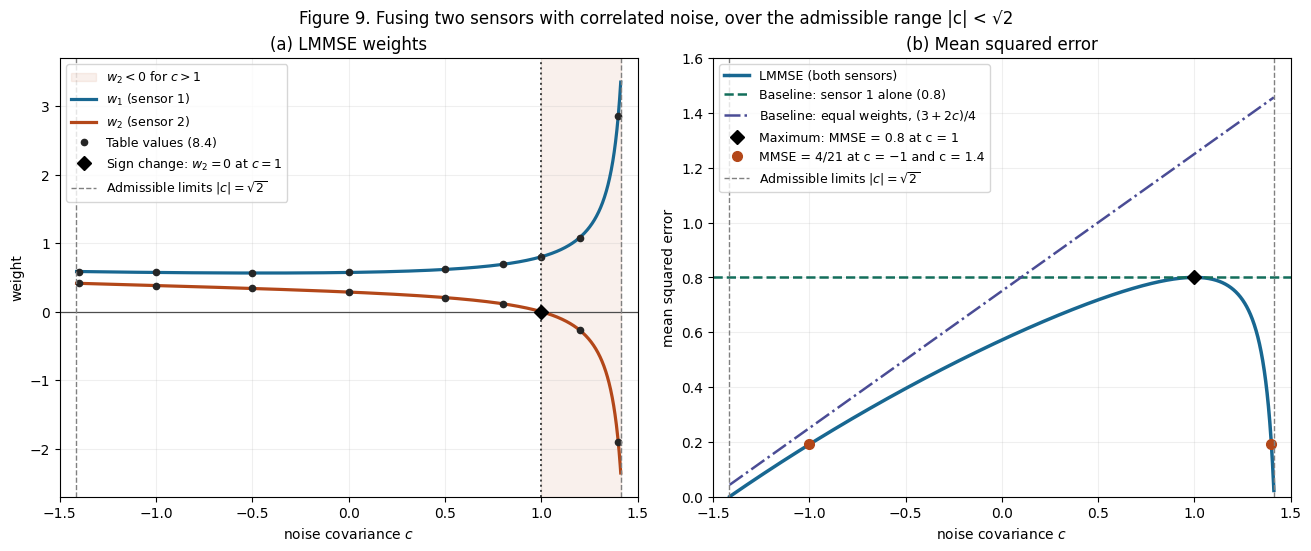

In [31]:
weights_color_step8 = ("#186791", "#b34719")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), layout="constrained")
fig.suptitle("Figure 9. Fusing two sensors with correlated noise, over the admissible range |c| < √2")

axis = axes[0]
axis.axvspan(1, c_limit_step8, color="#b34719", alpha=0.08, label=r"$w_2<0$ for $c>1$")
axis.axhline(0, color="0.3", linewidth=0.9)
for k, label in enumerate((r"$w_1$ (sensor 1)", r"$w_2$ (sensor 2)")):
    axis.plot(c_grid_step8, w_grid_step8[:, k], color=weights_color_step8[k], linewidth=2.3, label=label)
axis.plot(c_table_step8, table_weights_step8[:, 0], "o", color="0.15", ms=4.5)
axis.plot(c_table_step8, table_weights_step8[:, 1], "o", color="0.15", ms=4.5,
          label="Table values (8.4)")
axis.axvline(1, color="0.25", linestyle=":", linewidth=1.4)
axis.plot([1], [0], marker="D", color="black", ms=7, linestyle="none", label=r"Sign change: $w_2=0$ at $c=1$")
for edge, label in ((-c_limit_step8, r"Admissible limits $|c|=\sqrt{2}$"), (c_limit_step8, None)):
    axis.axvline(edge, color="0.5", linestyle="--", linewidth=1, label=label)
axis.set(title="(a) LMMSE weights", xlabel=r"noise covariance $c$", ylabel="weight",
         xlim=(-1.5, 1.5), ylim=(-2.7, 3.7))
axis.grid(alpha=0.2)
axis.legend(loc="upper left", fontsize=9)

axis = axes[1]
axis.plot(c_grid_step8, mmse_grid_step8, color="#186791", linewidth=2.5, label="LMMSE (both sensors)")
axis.axhline(best_single_step8, color="#136e5b", linewidth=1.8, linestyle="--",
             label=f"Baseline: sensor 1 alone ({best_single_step8:.1f})")
axis.plot(c_grid_step8, (3 + 2 * c_grid_step8) / 4, color="#4a4c95", linewidth=1.8, linestyle="-.",
          label=r"Baseline: equal weights, $(3+2c)/4$")
axis.plot([1], [mmse_at_1_step8], marker="D", color="black", ms=7, linestyle="none",
          label="Maximum: MMSE = 0.8 at c = 1")
axis.plot([-1, 1.4], [4 / 21, 4 / 21], marker="o", color="#b34719", ms=7, linestyle="none",
          label="MMSE = 4/21 at c = −1 and c = 1.4")
for edge, label in ((-c_limit_step8, r"Admissible limits $|c|=\sqrt{2}$"), (c_limit_step8, None)):
    axis.axvline(edge, color="0.5", linestyle="--", linewidth=1, label=label)
axis.set(title="(b) Mean squared error", xlabel=r"noise covariance $c$", ylabel="mean squared error",
         xlim=(-1.5, 1.5), ylim=(0, 1.6))
axis.grid(alpha=0.2)
axis.legend(loc="upper left", fontsize=9)
plt.show()

**Figure 9.** Panel (a) shows the weights from `lmmse_weights` at 2,001 values of $c$, with the table values from 8.4 as dots. $w_1$ stays near $0.57$ for negative and small $c$, then climbs steeply past $c=1$. $w_2$ falls steadily, crosses zero exactly at $c=1$, and is negative on the shaded region $c>1$, reaching $-1.904762$ at $c=1.4$. In panel (b) the sensor-1-alone baseline is the horizontal line at $0.8$. The equal-weight baseline cannot be horizontal, because its error $(3+2c)/4$ depends on $c$, so it is drawn as the sloped line. The closed forms in 8.5 agree with `lmmse_weights` to within $2.0\times10^{-14}$ over the whole grid. The fall of the MMSE on the positive side is so steep that $c=1.4$ already ties $c=-1$ at $4/21$.

### 8.8 The shape of the MMSE curve

The MMSE rises from zero as $c\to-\sqrt2$ to a single peak of $0.8$ at $c=1$ and falls back to zero as $c\to+\sqrt2$, so $c=1$ is the global maximum: it is the only admissible correlation at which the second sensor adds nothing, and every other $c$, positive or negative, gives strictly less error than sensor 1 alone. At $c=1$ the shared part of the noise reaches both sensors with the same 1:1 gains as the signal, so no weighting can remove one without the other. At either end of the range $\Sigma_N$ becomes singular and a fixed combination cancels the noise while keeping the signal ($\sqrt2X_1-X_2=(\sqrt2-1)S$ as $c\to\sqrt2$, and $\sqrt2X_1+X_2=(\sqrt2+1)S$ as $c\to-\sqrt2$), so the MMSE goes to zero at both ends; on the grid it is already 0.00069 at $c=-1.4128$ and 0.02277 at $c=1.4128$.

### 8.6 Why a negative weight is optimal

The difference $X_1-X_2=N_1-N_2$ contains no $S$ at all, and at $c=1.4$ its variance is $1+2-2c=0.2$, far below either sensor's own noise variance of $1$ or $2$, because the two noises move almost in lockstep: $N_2=1.4N_1+V$ with $\operatorname{Var}(V)=2-c^2=0.04$, so $X_1-X_2\approx-0.4N_1$ is mostly a rescaled copy of the noise on sensor 1. The estimator therefore treats sensor 2 as a noise reference rather than as a second look at $S$, the same idea behind differential signaling and noise-cancelling headphones. Rewriting it as $\hat S=(w_1+w_2)X_1-w_2(X_1-X_2)=0.952381\,X_1+1.904762\,(X_1-X_2)$ shows a slightly shrunk sensor 1 reading plus a correction, built from the signal-free difference, that cancels most of $N_1$. The negative $w_2$, together with a $w_1$ above $1$ that keeps the signal, is just that correction multiplied out, so subtracting a measurement of $S$ is the optimal move rather than a bug.

### 8.7 How can more correlated noise help?

At $c=1.4$ the MMSE is 0.190476, against 0.571429 at $c=0$, which is 3.0 times lower. Correlation does not add noise. It gives the noise a structure, and structured noise is predictable, so part of it can be cancelled. With $c=0$ neither sensor's noise says anything about the other's, and the best we can do is a weighted average whose noise only partly averages out. With $c=1.4$, $\Sigma_N$ has eigenvalues 0.0134 and 2.9866, so almost all of the noise lies along one direction in the measurement plane, and the nearly noise-free direction still carries part of the signal. The information form from 8.5, $\text{MMSE}=1/(1/\sigma_s^2+\mathbf 1^T\Sigma_N^{-1}\mathbf 1)$, puts a number on this: the information the two sensors supply, $\mathbf 1^T\Sigma_N^{-1}\mathbf 1$, grows from 1.5 at $c=0$ to 5.0 at $c=1.4$. What decides the error is not how noisy each sensor is on its own, but how much noise survives the best combination.

In [32]:
n_trials_step8 = 10**6
print(f"Monte Carlo: {n_trials_step8:,} independent trials for each value of c")
mc_results_step8 = {}
for c in (0.8, 1.4):
    weights, mmse = lmmse_solution_step8(c)
    Sigma_xx, Sigma_sx = fusion_statistics_step8(c)
    single_weight = lmmse_weights(Sigma_xx[:1, :1], Sigma_sx[:1])[0]
    # Draw S and N from separate standard normals, so S is independent of N by construction.
    z = rng_step8.standard_normal((n_trials_step8, 3))
    S = np.sqrt(sigma_s2_step8) * z[:, 0]
    N = z[:, 1:] @ np.linalg.cholesky(noise_covariance_step8(c)).T
    X = S[:, None] + N

    print(f"\nc = {c}: w = {np.round(weights, 6)}, sensor-1-alone weight = {single_weight:.1f}")
    print(f"  {'estimator':<24}{'simulated MSE':>14}{'SE':>10}{'analytic':>11}{'difference':>12}{'in SE':>8}")
    estimators = {
        "LMMSE (lmmse_weights)": (X @ weights, mmse),
        "Sensor 1 alone": (single_weight * X[:, 0], best_single_step8),
        "Equal weights": (X.mean(axis=1), (3 + 2 * c) / 4),
    }
    for name, (estimate, analytic) in estimators.items():
        squared_error = (S - estimate) ** 2
        mse = squared_error.mean()
        se = squared_error.std(ddof=1) / np.sqrt(n_trials_step8)
        mc_results_step8[(c, name)] = (mse, se, analytic)
        print(f"  {name:<24}{mse:14.6f}{se:10.6f}{analytic:11.6f}{mse - analytic:+12.2e}{(mse - analytic) / se:+8.2f}")

    error = S - X @ weights
    orthogonality = error[:, None] * X
    orthogonality_z = orthogonality.mean(axis=0) / (orthogonality.std(axis=0, ddof=1) / np.sqrt(n_trials_step8))
    print(f"  orthogonality E[(S - w^T X) X_k] = 0: sample means {orthogonality.mean(axis=0).round(5)}, "
          f"which are {orthogonality_z.round(2)} SE from zero")

    joint_theory = np.array([[4.0, 4.0, 4.0], [4.0, 5.0, 4.0 + c], [4.0, 4.0 + c, 6.0]])
    _, joint_sample = sample_mean_cov(np.column_stack([S, X]))
    joint_error_in_se = np.max(abs(joint_sample - joint_theory) / gaussian_covariance_se(joint_theory, n_trials_step8))
    print(f"  Cov([S, X1, X2]) against [[4, 4, 4], [4, 5, 4 + c], [4, 4 + c, 6]]: "
          f"largest entry error {joint_error_in_se:.2f} SE")

    difference = X[:, 0] - X[:, 1]
    var_difference = difference.var(ddof=1)
    var_difference_se = (3 - 2 * c) * np.sqrt(2 / (n_trials_step8 - 1))
    print(f"  Var(X1 - X2) = {var_difference:.6f} ± {var_difference_se:.6f}, theory 3 - 2c = {3 - 2 * c:.6f}, "
          f"difference {(var_difference - (3 - 2 * c)) / var_difference_se:+.2f} SE")

Monte Carlo: 1,000,000 independent trials for each value of c

c = 0.8: w = [0.689655 0.114943], sensor-1-alone weight = 0.8
  estimator                simulated MSE        SE   analytic  difference   in SE
  LMMSE (lmmse_weights)         0.782247  0.001106   0.781609   +6.37e-04   +0.58
  Sensor 1 alone                0.800493  0.001132   0.800000   +4.93e-04   +0.44
  Equal weights                 1.152882  0.001627   1.150000   +2.88e-03   +1.77
  orthogonality E[(S - w^T X) X_k] = 0: sample means [-0.00313 -0.00369], which are [-1.58 -1.7 ] SE from zero


  Cov([S, X1, X2]) against [[4, 4, 4], [4, 5, 4 + c], [4, 4 + c, 6]]: largest entry error 0.88 SE
  Var(X1 - X2) = 1.400711 ± 0.001980, theory 3 - 2c = 1.400000, difference +0.36 SE

c = 1.4: w = [ 2.857143 -1.904762], sensor-1-alone weight = 0.8
  estimator                simulated MSE        SE   analytic  difference   in SE
  LMMSE (lmmse_weights)         0.190722  0.000269   0.190476   +2.46e-04   +0.91
  Sensor 1 alone                0.800875  0.001131   0.800000   +8.75e-04   +0.77
  Equal weights                 1.449963  0.002051   1.450000   -3.74e-05   -0.02
  orthogonality E[(S - w^T X) X_k] = 0: sample means [0.00163 0.00157], which are [1.68 1.47] SE from zero
  Cov([S, X1, X2]) against [[4, 4, 4], [4, 5, 4 + c], [4, 4 + c, 6]]: largest entry error 0.51 SE


  Var(X1 - X2) = 0.199940 ± 0.000283, theory 3 - 2c = 0.200000, difference -0.21 SE


### 8.9 Monte Carlo check

With $10^6$ independent trials at each value, the simulated LMMSE error is $0.782247\pm0.001106$ at $c=0.8$ against the analytic 0.781609, a difference of 0.58 standard errors. At $c=1.4$ it is $0.190722\pm0.000269$ against 0.190476, a difference of 0.91 standard errors. The two baselines match their formulas within 1.77 standard errors, and the simulation reproduces the ordering in the table: at $c=1.4$ the plain average (1.449963) is worse than sensor 1 alone (0.800875), which is far worse than the fused estimate. Three structural checks also pass. The estimation error is uncorrelated with both measurements, as the orthogonality principle requires, with every sample mean of $(S-w^TX)X_k$ within 1.7 standard errors of zero. The sample covariance of $[S,X_1,X_2]$ matches the 8.1 derivation entry by entry, with the largest error at 0.88 standard errors. The simulated variance of $X_1-X_2$ at $c=1.4$ is $0.199940\pm0.000283$ against the analytic $0.2$, a difference of 0.21 standard errors.

In [33]:
def mse_with_weights_step8(weights, c_true):
    '''MSE of w^T X when the true noise covariance is c_true:
    S - w^T X = (1 - w^T 1) S - w^T N, so MSE = sigma_s^2 (1 - w^T 1)^2 + w^T Sigma_N w.'''
    return sigma_s2_step8 * (1 - weights.sum()) ** 2 + weights @ noise_covariance_step8(c_true) @ weights


designs_step8 = {
    "designed for c = 1.4": lmmse_solution_step8(1.4)[0],
    "designed for c = 0": lmmse_solution_step8(0.0)[0],
}
print("MSE when the weights are fixed at design time and the true c differs")
print("(the c = 0 design is what a designer gets by assuming independent noise)")
print(f"{'true c':>8}{'matched LMMSE':>15}" + "".join(f"{name:>22}" for name in designs_step8) + f"{'sensor 1 alone':>16}")
for c_true in (1.0, 1.2, 1.3, 1.35, 1.38, 1.4):
    row = f"{c_true:8.2f}{lmmse_solution_step8(c_true)[1]:15.6f}"
    row += "".join(f"{mse_with_weights_step8(weights, c_true):22.6f}" for weights in designs_step8.values())
    print(row + f"{best_single_step8:16.6f}")

# How much signal-free calibration data pins c down? With S absent, X = N, and
# the sample covariance entry has SE sqrt((sigma_1^2 sigma_2^2 + c^2) / (n - 1)) (Step 4's formula).
target_se_step8 = 0.01
calibration_n_step8 = int(np.ceil((1.0 * 2.0 + 1.4**2) / target_se_step8**2)) + 1
print(f"\nSignal-free samples needed to estimate c = 1.4 with standard error {target_se_step8}: {calibration_n_step8:,}")

MSE when the weights are fixed at design time and the true c differs
(the c = 0 design is what a designer gets by assuming independent noise)
  true c  matched LMMSE  designed for c = 1.4    designed for c = 0  sensor 1 alone
    1.00       0.800000              4.544218              0.897959        0.800000
    1.20       0.756757              2.367347              0.963265        0.800000
    1.30       0.649215              1.278912              0.995918        0.800000
    1.35       0.515426              0.734694              1.012245        0.800000
    1.38       0.362258              0.408163              1.022041        0.800000
    1.40       0.190476              0.190476              1.028571        0.800000

Signal-free samples needed to estimate c = 1.4 with standard error 0.01: 39,601


### 8.10 For a systems engineer

Specify the pair with highly correlated noise, but only if the correlation can be measured and kept stable; otherwise independent noise is the safer choice. In this model the best fusion reaches 0.571429 with independent noise and 0.190476 with $c=1.4$, because the second sensor doubles as a reference for the first one's noise. That gain comes from cancellation, so it is fragile: weights designed for $c=1.4$ give 1.278912 if the true $c$ is 1.3, worse than sensor 1 alone at 0.8, and ignoring the correlation altogether gives 1.028571 at $c=1.4$. To exploit it you need $c$ and both noise variances from a signal-free calibration, where $X=N$ and `sample_mean_cov` estimates $\Sigma_N$ directly (at $c=1.4$, 39,601 samples pin $c$ to a standard error of 0.01). You also need $c$ to stay put over temperature, supply voltage and aging, or an adaptive filter that tracks it, and you need the interference to reach the two sensors with a different gain ratio than the signal does, because at $c=1$ the shared noise looks exactly like the signal and the second sensor is worthless.

# Bonus A: Generating Correlated Vectors from Scratch

In this bonus, correlated Gaussian samples are generated using a standard normal random generator and matrix factorizations. The samples are generated in two ways: using Cholesky decomposition and using eigendecomposition.

## Why the Cholesky Method Works

Let \(z\) be a standard normal vector with covariance \(I\), and let

$$
x=Lz.
$$

The covariance of \(x\) is

$$
\operatorname{Cov}(x)
=
\operatorname{Cov}(Lz)
=
L\operatorname{Cov}(z)L^T.
$$

Since \(\operatorname{Cov}(z)=I\),

$$
\operatorname{Cov}(x)=LIL^T=LL^T.
$$

Therefore, if \(L\) is the Cholesky factor of \(\Sigma\), then \(LL^T=\Sigma\).

## Why the Eigendecomposition Method Works

For a symmetric covariance matrix,

$$
\Sigma=V\Lambda V^T.
$$

Using

$$
A=V\Lambda^{1/2},
$$

we generate

$$
x=Az.
$$

Its covariance is

$$
\operatorname{Cov}(x)
=
AA^T
=
V\Lambda^{1/2}
\left(V\Lambda^{1/2}\right)^T.
$$

This simplifies to

$$
\operatorname{Cov}(x)=V\Lambda V^T=\Sigma.
$$

In [34]:
N_bonus_A = 10**6

Sigma_bonus_2d = np.array([
    [4, 2],
    [2, 4]
], dtype=float)

Sigma_bonus_4d = Sigma_step3.copy()


def covariance_error(samples, target_covariance):
    _, estimated_covariance = sample_mean_cov(samples)

    return np.linalg.norm(
        estimated_covariance - target_covariance,
        ord="fro"
    )

In [35]:
bonus_results = []

bonus_matrices = {
    "2D covariance": Sigma_bonus_2d,
    "4D covariance": Sigma_bonus_4d
}

for matrix_name, target_covariance in bonus_matrices.items():
    dimension = target_covariance.shape[0]

    # Generate standard normal vectors using the assigned generator
    z = rng_bonus_A.standard_normal(
        size=(N_bonus_A, dimension)
    )

    # Cholesky method
    cholesky_factor = np.linalg.cholesky(
        target_covariance
    )

    cholesky_samples = z @ cholesky_factor.T

    cholesky_error = covariance_error(
        cholesky_samples,
        target_covariance
    )

    # Eigendecomposition method
    eigenvalues, eigenvectors = np.linalg.eigh(
        target_covariance
    )

    square_root_eigenvalue_matrix = np.diag(
        np.sqrt(eigenvalues)
    )

    eigen_factor = (
        eigenvectors
        @ square_root_eigenvalue_matrix
    )

    eigen_samples = z @ eigen_factor.T

    eigen_error = covariance_error(
        eigen_samples,
        target_covariance
    )

    bonus_results.append([
        matrix_name,
        cholesky_error,
        eigen_error
    ])

    print(f"\n{matrix_name}")
    print(f"Cholesky covariance error: {cholesky_error:.10f}")
    print(f"Eigendecomposition covariance error: {eigen_error:.10f}")
    print("Eigenvalues:")
    print(eigenvalues)


2D covariance
Cholesky covariance error: 0.0072255888
Eigendecomposition covariance error: 0.0065485664
Eigenvalues:
[2. 6.]



4D covariance
Cholesky covariance error: 0.0194962200
Eigendecomposition covariance error: 0.0151254390
Eigenvalues:
[1.26487889 1.78819531 3.09808432 7.84884147]


In [36]:
print(
    f"{'Matrix':<20}"
    f"{'Cholesky Error':>20}"
    f"{'Eigen Error':>20}"
)

for matrix_name, cholesky_error, eigen_error in bonus_results:
    print(
        f"{matrix_name:<20}"
        f"{cholesky_error:>20.10f}"
        f"{eigen_error:>20.10f}"
    )

Matrix                    Cholesky Error         Eigen Error
2D covariance               0.0072255888        0.0065485664
4D covariance               0.0194962200        0.0151254390


## Comparing the Two Methods

Both methods should produce covariance estimates close to the target covariance matrices. The small errors occur because only a finite number of random samples were used.

Cholesky decomposition is usually the cheaper method for generating samples because it only needs one triangular factor. Eigendecomposition calculates both eigenvalues and eigenvectors, so it usually requires more computation. However, eigendecomposition is useful when we want to understand the principal directions of the covariance matrix.

## Singular Covariance Matrix

A singular covariance matrix is positive semidefinite but not positive definite. Standard Cholesky decomposition requires the matrix to be positive definite, so it should fail for a singular matrix.

In [37]:
singular_covariance = np.array([
    [12, 24],
    [24, 48]
], dtype=float)

singular_eigenvalues, _ = np.linalg.eigh(
    singular_covariance
)

print("Singular covariance matrix:")
print(singular_covariance)

print(
    f"\nDeterminant: "
    f"{np.linalg.det(singular_covariance):.10f}"
)

print("\nEigenvalues:")
print(singular_eigenvalues)

try:
    singular_cholesky_factor = np.linalg.cholesky(
        singular_covariance
    )

    print("\nCholesky factor:")
    print(singular_cholesky_factor)

except np.linalg.LinAlgError as error:
    print("\nCholesky decomposition failed.")
    print(f"Error message: {error}")

Singular covariance matrix:
[[12. 24.]
 [24. 48.]]

Determinant: 0.0000000000

Eigenvalues:
[ 0. 60.]

Cholesky decomposition failed.
Error message: Matrix is not positive definite


The singular covariance matrix has a determinant of zero and at least one eigenvalue equal to zero. Because of this, it is not positive definite.

Cholesky decomposition fails because it requires every pivot to be positive. A singular covariance matrix has no full-rank triangular Cholesky factor, even though it can still represent a valid lower-dimensional random vector.

# Bonus B — Principal components on real data

We use R. A. Fisher's Iris measurements in the included iris.csv file. It contains the same measurements and species as the scikit-learn Iris dataset. For each flower, we use sepal length, sepal width, petal length, and petal width, all measured in centimeters. Species labels color the plot. We find the directions from the four measurements alone. [Dataset documentation](https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-plants-dataset)

In Step 6 we used the eigenvectors as axes for the sample cloud. PCA keeps the axes with the most spread. For a centered vector $X$ and a unit eigenvector $v$ with eigenvalue $\lambda$, the score on that axis is $v^TX$ and its variance is $v^T\Sigma v=\lambda$. We therefore project onto the two eigenvectors with the largest eigenvalues and divide their sum by the sum of all the eigenvalues to find the fraction of variance captured.

We first do this with centered measurements in centimeters. Then we divide each column by its own sample standard deviation and redo the covariance and eigendecomposition. Each standardized column has variance one, and its covariance with another standardized column is their Pearson correlation. This lets us see how much the original differences in feature spread influenced the directions.

Dataset size: 150 flowers, 4 numeric features
Sample standard deviations (cm):
  sepal length (cm): 0.8281
  sepal width (cm): 0.4359
  petal length (cm): 1.7653
  petal width (cm): 0.7622

Raw measurements (centered)
Covariance matrix:
[[ 0.68569 -0.04243  1.27432  0.51627]
 [-0.04243  0.18998 -0.32966 -0.12164]
 [ 1.27432 -0.32966  3.11628  1.29561]
 [ 0.51627 -0.12164  1.29561  0.58101]]
Eigenvalues (descending): [4.22824 0.24267 0.07821 0.02384]
PC1: 92.46%, PC2: 5.31%
Combined variance captured by PC1 and PC2: 97.77%
Eigenvector coefficients:
  sepal length (cm)  PC1 +0.361   PC2 +0.657
  sepal width (cm)   PC1 -0.085   PC2 +0.730
  petal length (cm)  PC1 +0.857   PC2 -0.173
  petal width (cm)   PC1 +0.358   PC2 -0.075

Standardized measurements
Covariance matrix:
[[ 1.      -0.11757  0.87175  0.81794]
 [-0.11757  1.      -0.42844 -0.36613]
 [ 0.87175 -0.42844  1.       0.96287]
 [ 0.81794 -0.36613  0.96287  1.     ]]
Eigenvalues (descending): [2.9185  0.91403 0.14676 0.02071]
PC1

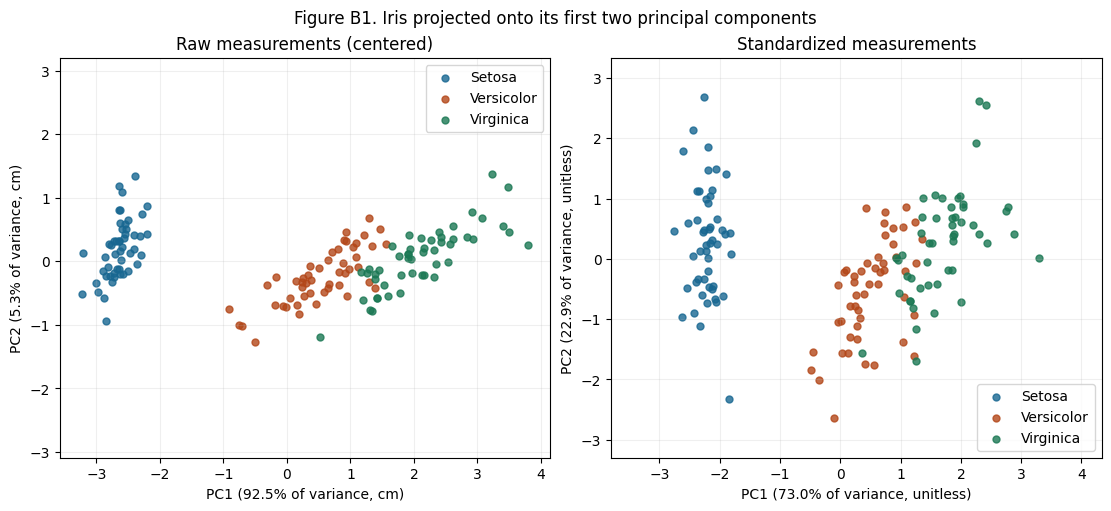

In [38]:
from pathlib import Path

import mp3lib

# The CSV ships beside the project module.
iris_path = Path(mp3lib.__file__).with_name("iris.csv")
iris_rows = np.loadtxt(iris_path, delimiter=",", skiprows=1, dtype=str)
features_bonus_B = iris_rows[:, :4].astype(float)
species_bonus_B = iris_rows[:, 4]
feature_names_bonus_B = (
    "sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)",
)
mean_bonus_B, covariance_bonus_B = sample_mean_cov(features_bonus_B)
centered_bonus_B = features_bonus_B - mean_bonus_B
std_bonus_B = np.sqrt(np.diag(covariance_bonus_B))
standardized_bonus_B = centered_bonus_B / std_bonus_B

print(f"Dataset size: {features_bonus_B.shape[0]} flowers, {features_bonus_B.shape[1]} numeric features")
print("Sample standard deviations (cm):")
for name, deviation in zip(feature_names_bonus_B, std_bonus_B):
    print(f"  {name}: {deviation:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
fig.suptitle("Figure B1. Iris projected onto its first two principal components")
colors_bonus_B = ["#186791", "#b34719", "#1b7854"]

for axis, data, title, unit in zip(
    axes,
    [centered_bonus_B, standardized_bonus_B],
    ["Raw measurements (centered)", "Standardized measurements"],
    ["cm", "unitless"],
):
    _, covariance = sample_mean_cov(data)
    eigenvalues, directions = np.linalg.eigh(covariance)
    eigenvalues = eigenvalues[::-1]
    directions = directions[:, ::-1]
    # Fix each sign for a consistent plot orientation across runs.
    pivot_rows = np.argmax(abs(directions), axis=0)
    directions *= np.sign(directions[pivot_rows, np.arange(directions.shape[1])])
    variance_share = eigenvalues / eigenvalues.sum()
    scores = data @ directions[:, :2]

    print(f"\n{title}")
    print(f"Covariance matrix:\n{np.round(covariance, 5)}")
    print(f"Eigenvalues (descending): {np.round(eigenvalues, 5)}")
    print(f"PC1: {variance_share[0]:.2%}, PC2: {variance_share[1]:.2%}")
    print(f"Combined variance captured by PC1 and PC2: {variance_share[:2].sum():.2%}")
    print("Eigenvector coefficients:")
    for name, coefficients in zip(feature_names_bonus_B, directions[:, :2]):
        print(f"  {name:18s} PC1 {coefficients[0]:+.3f}   PC2 {coefficients[1]:+.3f}")

    for species, color in zip(np.unique(species_bonus_B), colors_bonus_B):
        class_scores = scores[species_bonus_B == species]
        axis.scatter(*class_scores.T, s=25, alpha=0.8, label=species.capitalize(), color=color)

    axis.set(
        title=title,
        xlabel=f"PC1 ({variance_share[0]:.1%} of variance, {unit})",
        ylabel=f"PC2 ({variance_share[1]:.1%} of variance, {unit})",
    )
    axis.set_aspect("equal", adjustable="datalim")
    axis.grid(alpha=0.2)
    axis.legend(loc="best")

plt.show()

**Figure B1.** On the left, petal length has the largest raw standard deviation and the largest coefficient on PC1. The first two axes capture 97.77% of the raw variance. After standardizing, sepal width has the largest coefficient on PC2, and that axis captures 22.85% of the variance compared with 5.31% before. The first two axes now capture 95.81% of the standardized variance. The two fractions describe variation on their respective measurement scales. I would use the standardized view to compare overall flower shape, since the narrower-spread measurements get equal starting variance. The raw view is useful for preserving the largest absolute differences in centimeters.

In [39]:
runtime_seconds = time.perf_counter() - runtime_start
print(f"Total runtime, Steps 1-8 and both bonus sections: {runtime_seconds:.2f} s")

Total runtime, Steps 1-8 and both bonus sections: 8.61 s
